# Result — all seven IR experiments

This notebook presents the **saved results supplied in `IR_Project_final.zip`**.
It has one result cell for each notebook in `experiments/`, in numerical order.
Each cell shows its principal tables, the original saved plots, and an expandable
catalog of the remaining output files. Comments and accompanying text explain
both the calculations and their interpretation.

**Use:** place this file in `Local/`, next to `experiments/`, `results/`, and `src/`,
and choose **Restart Kernel and Run All**. Saved outputs are already embedded for
viewing. Rerunning the report reads the current result files; it does **not**
retrain models, execute the experiment notebooks, or overwrite their outputs.
Only `numpy`, `pandas`, and `IPython` are needed to regenerate this report.

To produce a new experiment run, execute its corresponding notebook in
`experiments/` first, then rerun this report. Corpus preparation, if needed, is
in `src/preprocessing.ipynb`. This report checks saved table arithmetic, but
those checks do not independently reproduce model training or prove that the
saved outputs came from the currently supplied source version.

1. [PLSA baseline](#experiment-01)
2. [Six broad subject groups](#experiment-02)
3. [All-20 topic-count study](#experiment-03)
4. [Retrieval scoring investigation](#experiment-04)
5. [Validation and query study](#experiment-05)
6. [Bagging and restart ensembles](#experiment-06)
7. [Topic-mixture and boundary experiment](#experiment-07)

## Common workflow and metric meanings

`src/preprocessing.ipynb` loads all 20 Newsgroups categories, removes headers,
footers and quoted text, and applies spaCy filtering and lemmatization. The
processed text and labels are saved to `data/20news_preprocessed.npz`. Each
experiment then chooses its corpus/relevance labels and a stratified split.
Count and TF-IDF vocabularies are fitted on **training text only** (at most
3,000 terms, `min_df=3`, `max_df=0.90`).

The shared `src/plsa_model.py` fits PLSA by EM and selects restarts by training
log-likelihood. Fold-in infers a new document's topic mixture while holding the
topic-word probabilities fixed. TF-IDF/LSI use cosine similarity. PLSA uses
cosine in topic space, or query log-likelihood
`sum_w count(query,w) * log(sum_z P(z|document) * P(w|z))`, with the numerical
floor/background mixture described in the relevant experiment.

`src/evaluation.py` uses **binary category/group relevance**:

| Output | Meaning and calculation |
|---|---|
| Precision@10 | Relevant documents in the first 10 ranks, divided by **10** (the supplied implementation always uses k as denominator). |
| Recall@10 | Relevant documents in the first 10 ranks, divided by all relevant documents in the eligible candidate collection. |
| AP@10 | Sum of precision at relevant ranks up to 10, divided by `min(10, total relevant)`. This is a per-query score. |
| MAP@10 | Arithmetic mean of AP@10 across the fixed queries; each query has equal weight. |
| NDCG@10 | Discounted binary relevance using `1/log2(rank+1)`, divided by ideal DCG. |
| Training log-likelihood | Training word-count fit; less negative is better **on the same training matrix**. It is not retrieval accuracy. |
| NMI / ARI | Agreement between dominant topics and evaluation groups, reported only in experiment 02. |

The baseline retains all test candidates; experiments 02–06 exclude texts empty
after preprocessing. This is not the same as excluding zero vectors after
vocabulary filtering. Experiment 07 is a synthetic training-source probe, not a
held-out retrieval test. Compare methods **within the same experiment**; corpus,
splits, queries and relevance definitions differ across the seven sections.

In [1]:
# Setup: this cell only reads files and defines presentation/checking helpers.
# Set PROJECT_ROOT explicitly if you launch the notebook from another directory.
from pathlib import Path
import hashlib
import html
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML, Image, FileLink

PROJECT_ROOT = None  # Example: Path('/path/to/Local')
EXPERIMENTS = [
    ('01', 'plsa_baseline', '01_plsa_baseline.ipynb'),
    ('02', 'six_category_experiment', '02_six_category_experiment.ipynb'),
    ('03', 'all20_k_study', '03_all20_k_study.ipynb'),
    ('04', 'retrieval_scoring_investigation', '04_retrieval_scoring_investigation.ipynb'),
    ('05', 'retrieval_validation_query_study', '05_retrieval_validation_query_study.ipynb'),
    ('06', 'bagging_experiment', '06_bagging_experiment.ipynb'),
    ('07', 'topic_boundary_experiment', '07_topic_boundary_experiment.ipynb'),
]
if PROJECT_ROOT is None:
    candidates = [Path.cwd(), Path.cwd() / 'Local', Path.cwd().parent]
    PROJECT_ROOT = next((p for p in candidates if all(
        (p / 'results' / folder / 'configuration.json').is_file()
        for _, folder, _ in EXPERIMENTS
    )), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Place Result.ipynb in Local/ beside results/, or set PROJECT_ROOT.')
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
RESULTS_ROOT = PROJECT_ROOT / 'results'
TABLES = {}
SEEN_FILES = set()
CHECKS = []

# Normalize presentation labels only. Source CSV files remain untouched.
def normalized(frame):
    return frame.rename(columns={
        'Method': 'method', 'Precision@k': 'Precision@10',
        'Recall@k': 'Recall@10', 'AP@k': 'AP@10',
        'MAP@k': 'MAP@10', 'NDCG@k': 'NDCG@10',
    })

def read_table(folder, filename):
    path = RESULTS_ROOT / folder / filename
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}; run the corresponding experiment first.')
    SEEN_FILES.add(path)
    # This one CSV was exported from a two-level (K, method) pivot table.
    # A single header row would incorrectly treat metadata as numerical rows.
    if filename == 'test_ap_by_query.csv':
        return pd.read_csv(path, header=[0, 1], index_col=0)
    return normalized(pd.read_csv(path))

def config(folder):
    path = RESULTS_ROOT / folder / 'configuration.json'
    SEEN_FILES.add(path)
    return json.loads(path.read_text(encoding='utf-8'))

def show_table(frame, title, explanation, max_rows=30):
    display(Markdown(f'### {title}\n\n{explanation}'))
    # Small summaries are shown in full; large detail tables have an explicit preview.
    preview = frame.head(max_rows)
    display(HTML(preview.to_html(index=not isinstance(frame.index, pd.RangeIndex),
                                float_format=lambda x: f'{x:.4f}', escape=True)))
    if len(frame) > max_rows:
        display(Markdown(f'*Showing {max_rows} of {len(frame):,} rows. Full table: output-file catalog below.*'))

def show_plot(folder, filename, explanation):
    path = RESULTS_ROOT / folder / filename
    if not path.is_file():
        raise FileNotFoundError(f'Missing saved plot: {path}')
    SEEN_FILES.add(path)
    display(Markdown(explanation))
    # Embed the original image so it remains visible after the notebook is shared.
    display(Image(data=path.read_bytes(), width=920, embed=True))

def check_close(actual, saved, description):
    np.testing.assert_allclose(np.asarray(actual, dtype=float),
                               np.asarray(saved, dtype=float), rtol=1e-8, atol=1e-10,
                               equal_nan=True, err_msg=description)
    CHECKS.append(description)

def check_macro(raw, saved, groups=('method',), description='Macro-average agrees with query scores'):
    metrics = ['Precision@10', 'Recall@10', 'AP@10', 'NDCG@10']
    computed = raw.groupby(list(groups), dropna=False)[metrics].mean().rename(columns={'AP@10': 'MAP@10'})
    # Merge on explicit keys: unlike MultiIndex.reindex, this correctly matches
    # baseline rows whose K is NaN because topic count is not applicable.
    expected = saved[list(groups) + list(computed.columns)]
    joined = computed.reset_index().merge(expected, on=list(groups), how='outer',
                                           suffixes=('_computed', '_saved'),
                                           indicator=True, validate='one_to_one')
    assert joined['_merge'].eq('both').all(), description + ': mismatched summary groups'
    check_close(joined[[c + '_computed' for c in computed.columns]],
                joined[[c + '_saved' for c in computed.columns]], description)

def finding(summary):
    # Interpret the observed table without claiming statistical significance.
    ordered = summary.sort_values('MAP@10', ascending=False)
    best = ordered.iloc[0]
    display(Markdown(f"**Observed in this saved run:** {best['method']} has the highest "
                     f"MAP@10 in this table ({best['MAP@10']:.4f}). "
                     'This is a comparison on the stated fixed query set, not a universal ranking of methods.'))

def context(folder, notebook):
    settings = config(folder)
    display(Markdown(f'**Source:** `experiments/{notebook}`  \n**Saved outputs:** `results/{folder}/`'))
    display(HTML('<details><summary>Complete saved experiment settings</summary><pre>' +
                 html.escape(json.dumps(settings, indent=2)) + '</pre></details>'))
    return settings

# Every additional CSV/JSON/NPZ/PNG is listed, including large per-query/member tables.
def output_catalog(folder):
    entries = []
    for path in sorted((RESULTS_ROOT / folder).iterdir()):
        if not path.is_file():
            continue
        SEEN_FILES.add(path)
        relative = path.relative_to(PROJECT_ROOT).as_posix()
        link = f'<a href="{html.escape(relative, quote=True)}">{html.escape(path.name)}</a>'
        if path.suffix == '.csv':
            frame = read_table(folder, path.name)
            preview = frame.head(12).to_html(index=not isinstance(frame.index, pd.RangeIndex),
                                           float_format=lambda x: f'{x:.4f}', escape=True)
            entries.append(f'<details><summary>{html.escape(path.name)} — {len(frame):,} rows, '
                           f'{len(frame.columns)} columns</summary><p>{link}</p>{preview}'
                           '<p>Preview: up to 12 rows; open the CSV for the full table.</p></details>')
        elif path.suffix == '.json':
            entries.append('<details><summary>' + html.escape(path.name) + '</summary><p>' + link +
                           '</p><pre>' + html.escape(json.dumps(json.loads(path.read_text()), indent=2)) + '</pre></details>')
        elif path.suffix == '.npz':
            with np.load(path, allow_pickle=False) as archive:
                shapes = {key: list(archive[key].shape) for key in archive.files}
            entries.append('<details><summary>' + html.escape(path.name) + '</summary><p>' + link +
                           '</p><p>Exact saved bootstrap row indices, one array per member:</p><pre>' +
                           html.escape(json.dumps(shapes, indent=2)) + '</pre></details>')
        else:
            entries.append('<p>' + link + '</p>')
    display(HTML('<details><summary><b>All saved output files — tables, settings, plots and arrays</b></summary>' +
                 ''.join(entries) + '</details>'))

print('Reading saved artifacts from:', RESULTS_ROOT)
print('Seven experiment sections ready. No training or experiment code is executed by this report.')

Reading saved artifacts from: /workspace/work/teammate-ir/Local/results
Seven experiment sections ready. No training or experiment code is executed by this report.


<a id="experiment-01"></a>
## 01 — PLSA baseline on all 20 categories

**How generated:** use all 18,846 documents with a stratified 75/25 split; fit
K=5 PLSA with five seeds and retain the highest training-likelihood restart.
Fit TF-IDF and 50-component LSI on the same training text. One fixed keyword
query per category ranks all test documents using cosine; average the 20
query-level metric values. This establishes the single-model reference.

**What to read:** the retrieval table measures ranking quality, the restart
and convergence outputs measure optimization, and topic words describe the
learned distributions. The mixture probe samples 300 tokens from baseball and
`talk.politics.misc` training documents at five known source ratios, with 20
replicates per ratio, then folds them into the chosen PLSA model. Its error bars
are standard deviations across generated documents. A topic probability need
not equal a token-source proportion.

**Source:** `experiments/01_plsa_baseline.ipynb`  
**Saved outputs:** `results/plsa_baseline/`

### Held-out retrieval — 20 category queries

Mean query metrics; @k in the source CSV means @10 in this run.

method,Precision@10,Recall@10,NDCG@10,MAP@10
LSI,0.6900,0.0288,0.7000,0.6036
PLSA,0.1550,0.0065,0.1657,0.0734
TF-IDF/VSM,0.7300,0.0304,0.7459,0.6541


**Observed in this saved run:** TF-IDF/VSM has the highest MAP@10 in this table (0.6541). This is a comparison on the stated fixed query set, not a universal ranking of methods.

### PLSA restart selection

The selected flag identifies the largest training log-likelihood, not the best test retrieval score.

restart,seed,iterations,training_log_likelihood,selected
1,42,43,-5995748.4339,False
2,43,50,-5993380.3811,False
3,44,51,-5989043.2263,True
4,45,48,-6003355.0635,False
5,46,54,-5995924.9014,False


### Top words per learned topic

Each row is a word ranked by P(word|topic). Topic IDs are arbitrary.

topic,rank,word,probability
0,1,key,0.0091
0,2,government,0.0074
0,3,gun,0.0072
0,4,use,0.0067
0,5,public,0.0061
0,6,information,0.0059
0,7,law,0.0057
0,8,system,0.0052
0,9,number,0.0051
0,10,state,0.0050


**Retrieval comparison:** saved macro-average plot.

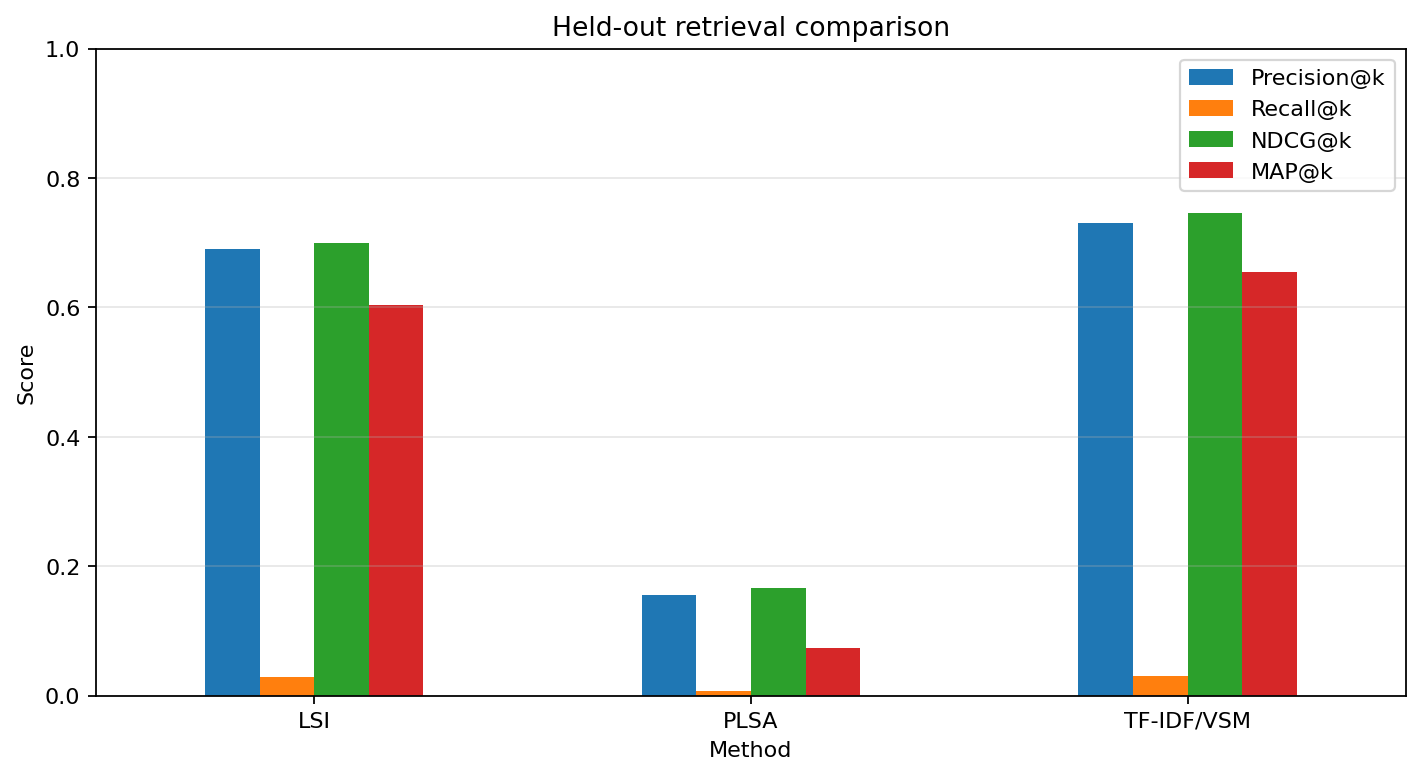

**Convergence:** training log-likelihood after each EM iteration.

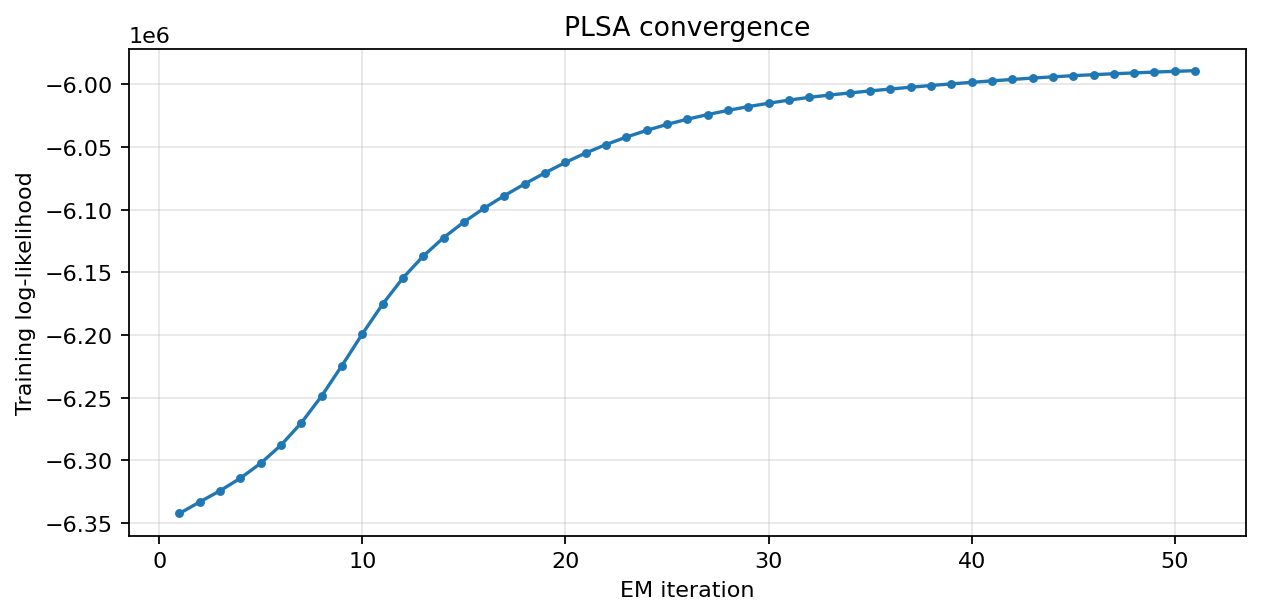

### Synthetic source-mixture response

Mean and sample standard deviation of the selected source-associated topic probabilities across replicates.

actual_sports_word_ratio,estimated_sports_mean,estimated_sports_std,estimated_politics_mean,estimated_politics_std
0.1000,0.1806,0.1608,0.4841,0.2669
0.3000,0.2912,0.2097,0.3800,0.2977
0.5000,0.4612,0.2396,0.1854,0.1981
0.7000,0.5587,0.2463,0.1695,0.1619
0.9000,0.6185,0.2426,0.1785,0.1725


**Mixture response:** the diagonal is a reference, not a guaranteed calibration law.

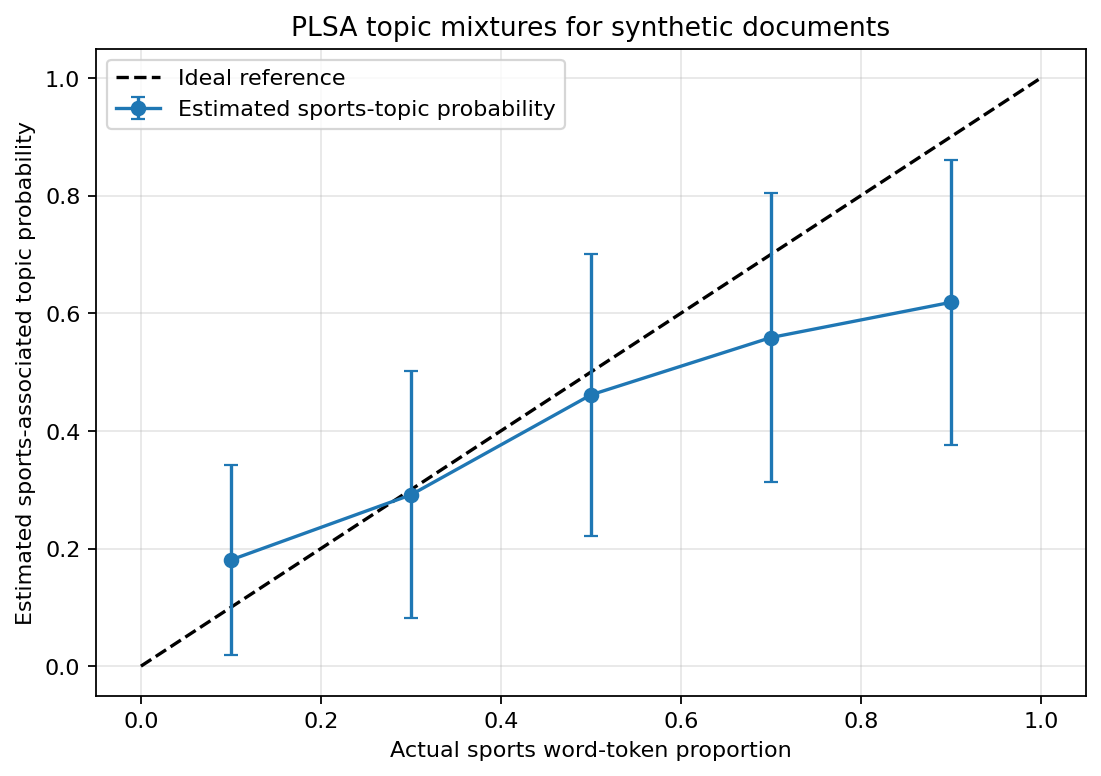

iteration,training_log_likelihood
1,-6342223.7042
2,-6333044.0327
3,-6324128.4921
4,-6314096.4434
5,-6302220.2419
6,-6287749.8519
7,-6269939.7517
8,-6248551.1195
9,-6224301.7874
10,-6199126.7621


In [2]:
# EXPERIMENT 01: expose the baseline's saved outputs without fitting a new model.
folder = 'plsa_baseline'
settings = context(folder, '01_plsa_baseline.ipynb')
raw = read_table(folder, 'retrieval_metrics_by_query.csv')
summary = read_table(folder, 'retrieval_metrics_mean.csv')
# Recompute the mean of each query metric to verify the saved summary.
check_macro(raw, summary, description='01: macro metrics match 20-query table')
TABLES['01'] = summary
show_table(summary, 'Held-out retrieval — 20 category queries',
           'Mean query metrics; @k in the source CSV means @10 in this run.')
finding(summary)
show_table(read_table(folder, 'restart_summary.csv'), 'PLSA restart selection',
           'The selected flag identifies the largest training log-likelihood, not the best test retrieval score.')
show_table(read_table(folder, 'topic_words.csv'), 'Top words per learned topic',
           'Each row is a word ranked by P(word|topic). Topic IDs are arbitrary.', max_rows=60)
show_plot(folder, 'retrieval_metrics_comparison.png', '**Retrieval comparison:** saved macro-average plot.')
show_plot(folder, 'plsa_convergence.png', '**Convergence:** training log-likelihood after each EM iteration.')
show_table(read_table(folder, 'synthetic_mixture_summary.csv'), 'Synthetic source-mixture response',
           'Mean and sample standard deviation of the selected source-associated topic probabilities across replicates.')
show_plot(folder, 'synthetic_mixture_topic_probabilities.png',
          '**Mixture response:** the diagonal is a reference, not a guaranteed calibration law.')
output_catalog(folder)

<a id="experiment-02"></a>
## 02 — Six broad subject groups

Despite its filename, this experiment retains **all 20 original categories**
and maps them to six broad groups; it does not train on only six categories.
It uses an 80/20 split stratified by group, K=6, five PLSA restarts, and one
query for each group. All methods rank the same non-empty processed test texts.
The group mapping is recorded in the expandable settings.

**How generated:** compute category/group relevance scores for the six queries
and average them. NMI and ARI compare the dominant topic of each eligible test
document with its group label; these are clustering diagnostics, not retrieval
metrics. The centroid diagnostic compares training TF-IDF category centroids
within a group and against categories outside it. The follow-up mixture probe
combines baseball and `talk.politics.guns` training documents, using the same
five ratios/20 replicates as the baseline.

**Interpretation:** K=6 does not force topics to equal the six human groups.
Compare the methods in this table rather than directly treating a change from
experiment 01 as a causal effect of grouping: the split and queries also differ.

**Source:** `experiments/02_six_category_experiment.ipynb`  
**Saved outputs:** `results/six_category_experiment/`

### Held-out retrieval — six group queries

Mean metrics over the six fixed group queries.

method,Precision@10,Recall@10,MAP@10,NDCG@10
TF-IDF/VSM,0.8833,0.0166,0.8189,0.8982
LSI,0.8333,0.0167,0.7155,0.8077
PLSA,0.4333,0.0068,0.2858,0.4248


**Observed in this saved run:** TF-IDF/VSM has the highest MAP@10 in this table (0.8189). This is a comparison on the stated fixed query set, not a universal ranking of methods.

### Dominant-topic / group alignment

NMI and ARI compare held-out dominant topics with group labels; documents gives the eligible count.

NMI,ARI,documents
0.3062,0.2306,3649


### Training category-centroid diagnostic

Within-group versus external-category cosine similarity tests the proposed grouping descriptively.

supergroup,source_categories,mean_within_group_cosine,mean_to_other_groups_cosine,closest_external_category
Computing,5,0.6085,0.3548,sci.electronics
Digital technology and engineering,2,0.5253,0.4311,comp.graphics
Health and space science,2,0.4855,0.4227,talk.politics.misc
Recreation and consumer exchange,5,0.4016,0.3547,sci.electronics
Religion and worldview,3,0.8184,0.3907,talk.politics.misc
Politics and international affairs,3,0.6213,0.4013,talk.religion.misc


### Top words for the six topics

The top 12 words per topic come from the selected model’s topic-word probabilities.

topic,rank,word,probability
0,1,year,0.0077
0,2,say,0.0065
0,3,people,0.0063
0,4,new,0.0058
0,5,president,0.0058
0,6,go,0.0052
0,7,state,0.0049
0,8,government,0.0049
0,9,report,0.0049
0,10,national,0.0048


**Retrieval comparison:** six queries, shared test candidates.

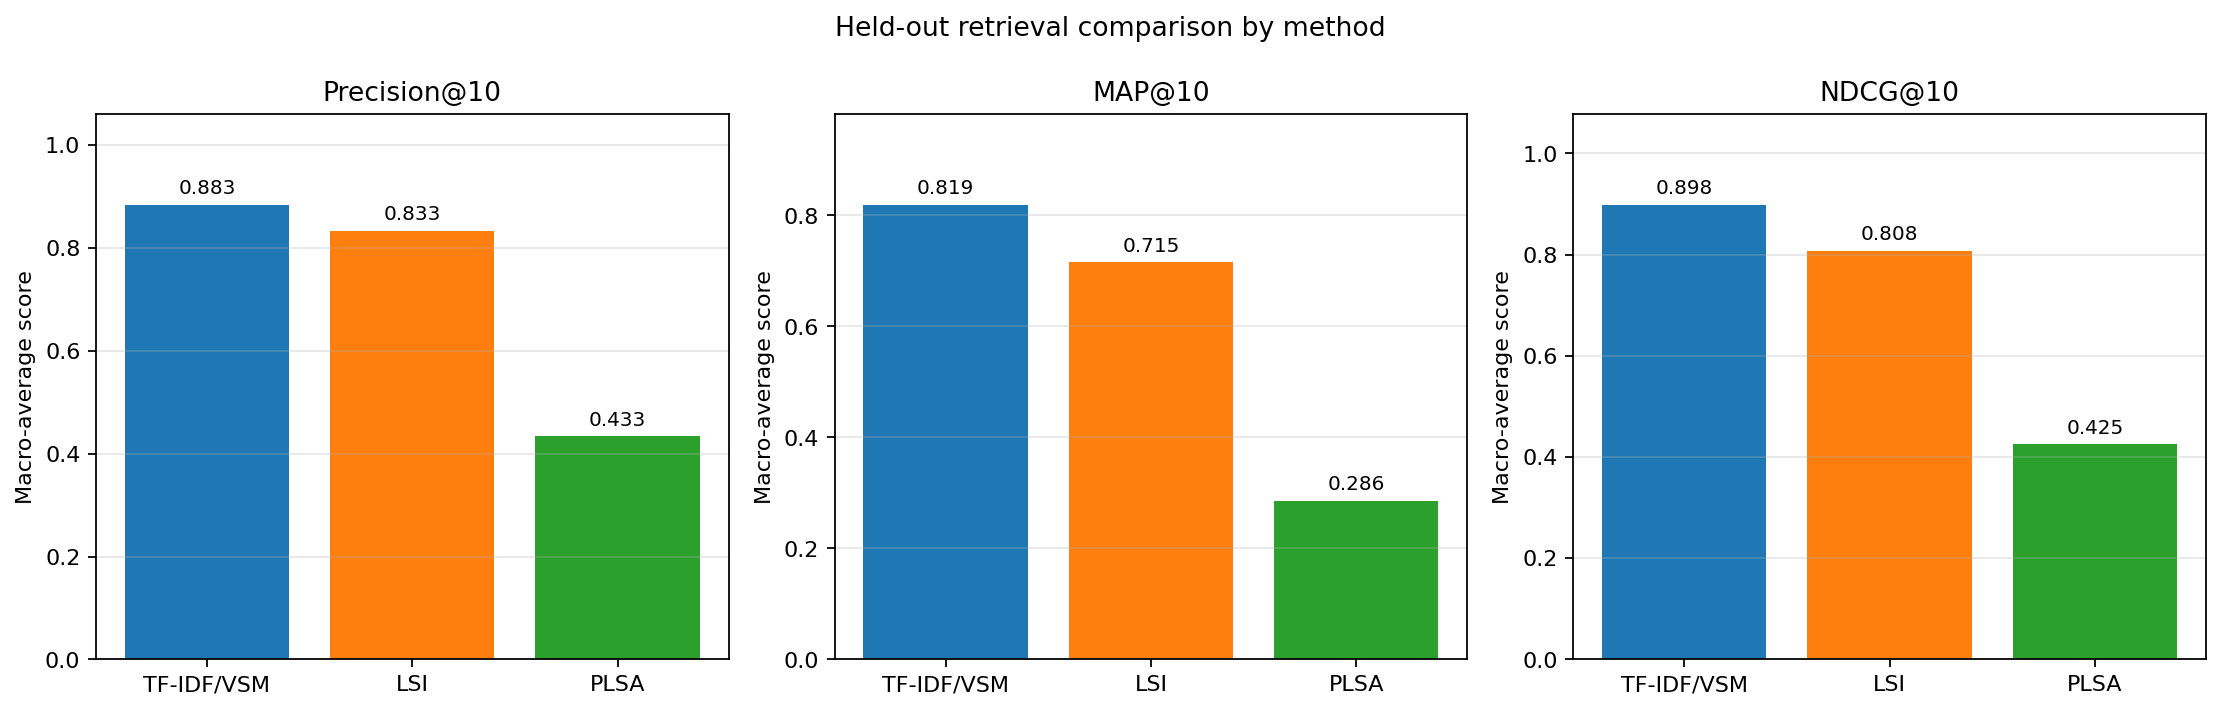

**Convergence:** training fit of the selected restart.

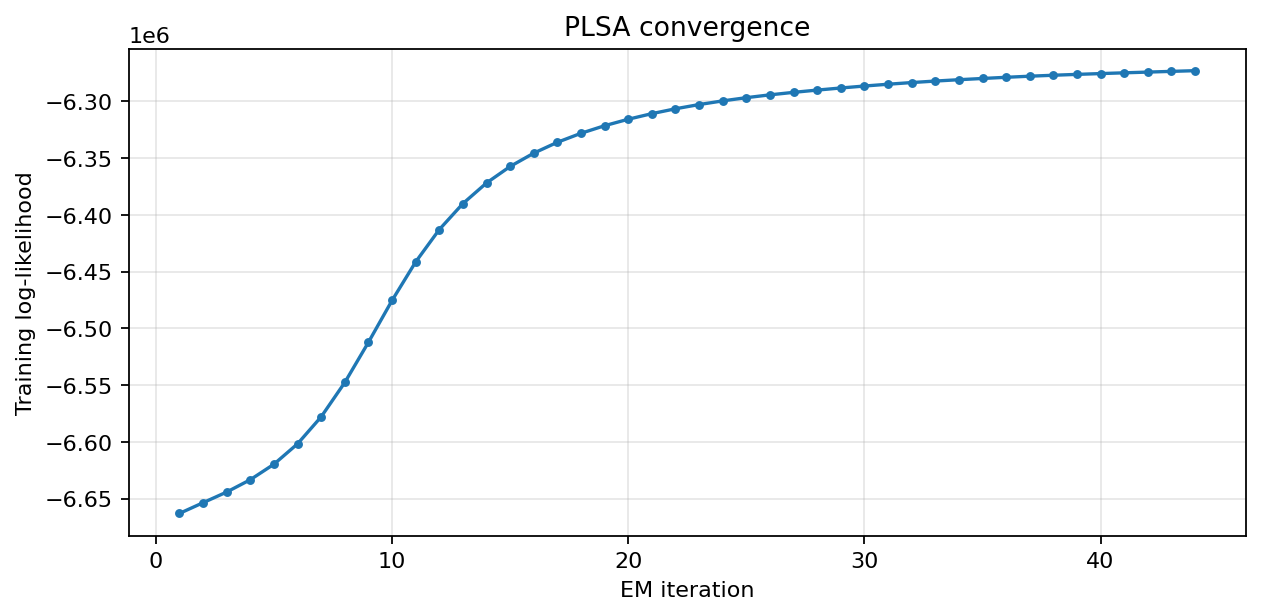

### Baseball / gun-politics mixture response

Topic-probability means and standard deviations across synthetic replicates.

actual_sports_word_ratio,estimated_sports_mean,estimated_sports_std,estimated_politics_mean,estimated_politics_std
0.1000,0.0789,0.0714,0.3996,0.2791
0.3000,0.2015,0.1586,0.3748,0.2811
0.5000,0.3884,0.1518,0.2460,0.1801
0.7000,0.4884,0.2343,0.1963,0.1388
0.9000,0.6816,0.2776,0.0791,0.0858


**Synthetic response:** source ratios versus inferred topic weights.

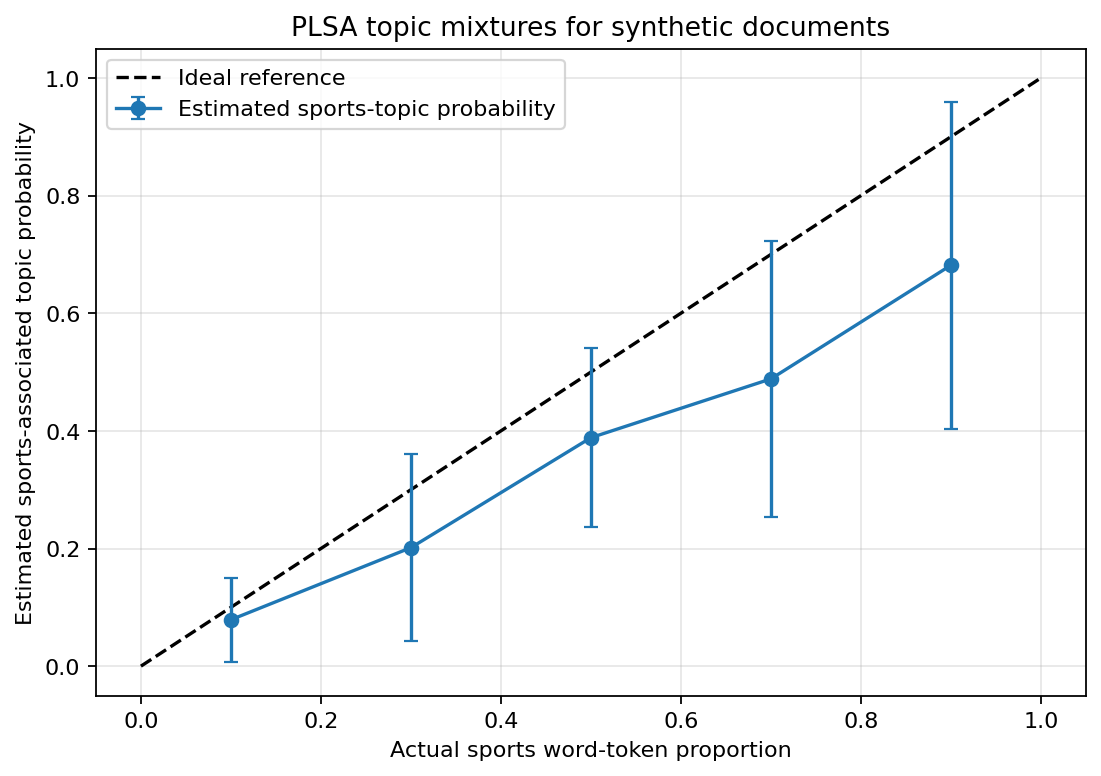

iteration,training_log_likelihood
1,-6662995.1959
2,-6653546.5870
3,-6644164.4603
4,-6633289.4487
5,-6619644.2229
6,-6601682.7722
7,-6577891.0236
8,-6547642.9228
9,-6512271.3232
10,-6475431.8569


In [3]:
# EXPERIMENT 02: six evaluation groups over the complete corpus.
folder = 'six_category_experiment'
settings = context(folder, '02_six_category_experiment.ipynb')
summary = read_table(folder, 'retrieval_metrics_mean.csv')
check_macro(read_table(folder, 'retrieval_metrics_by_query.csv'), summary,
            description='02: macro metrics match six-group query table')
TABLES['02'] = summary
show_table(summary, 'Held-out retrieval — six group queries', 'Mean metrics over the six fixed group queries.')
finding(summary)
show_table(read_table(folder, 'plsa_topic_group_alignment.csv'), 'Dominant-topic / group alignment',
           'NMI and ARI compare held-out dominant topics with group labels; documents gives the eligible count.')
show_table(read_table(folder, 'supergroup_centroid_similarity.csv'), 'Training category-centroid diagnostic',
           'Within-group versus external-category cosine similarity tests the proposed grouping descriptively.')
show_table(read_table(folder, 'topic_words.csv'), 'Top words for the six topics',
           'The top 12 words per topic come from the selected model’s topic-word probabilities.', max_rows=72)
show_plot(folder, 'retrieval_metrics_comparison.png', '**Retrieval comparison:** six queries, shared test candidates.')
show_plot(folder, 'plsa_convergence.png', '**Convergence:** training fit of the selected restart.')
show_table(read_table(folder, 'synthetic_mixture_summary.csv'), 'Baseball / gun-politics mixture response',
           'Topic-probability means and standard deviations across synthetic replicates.')
show_plot(folder, 'synthetic_mixture_topic_probabilities.png', '**Synthetic response:** source ratios versus inferred topic weights.')
output_catalog(folder)

<a id="experiment-03"></a>
## 03 — All-20 topic-count study

**How generated:** keep all categories and 20 queries fixed; use a 60/20/20
train/validation/test split. For K in `{2, 5, 8, 10, 20}`, retain the best of
three training-likelihood restarts. Fold validation/test documents into each
model and score queries with both PLSA cosine and query likelihood. TF-IDF/LSI
are fitted once and appear once in the test summary.

**Selection versus evaluation:** validation MAP@10 selects K separately for
each PLSA scoring rule, with Precision@10 as a tie-break. The selected-settings
test table is the main comparison. The full test curve is the predeclared
sensitivity study; it must not be used to choose K again. A larger training
likelihood at larger K is not by itself a retrieval improvement.

**Source:** `experiments/03_all20_k_study.ipynb`  
**Saved outputs:** `results/all20_k_study/`

### Settings selected on validation

Selection is based only on validation results.

method,selected_K
PLSA cosine,20
PLSA query likelihood,20


### Held-out test at the selected K

A blank K for TF-IDF/LSI means PLSA topic count is not applicable.

K,method,Precision@10,Recall@10,MAP@10,NDCG@10
20.0000,PLSA cosine,0.3950,0.0218,0.2495,0.3664
20.0000,PLSA query likelihood,0.4000,0.0220,0.2573,0.3755
NaN,LSI,0.7400,0.0401,0.6516,0.7308
NaN,TF-IDF/VSM,0.7350,0.0398,0.6560,0.7620


**Observed in this saved run:** TF-IDF/VSM has the highest MAP@10 in this table (0.6560). This is a comparison on the stated fixed query set, not a universal ranking of methods.

### Validation sensitivity to K

Mean AP across 20 validation queries is MAP@10.

K,method,Precision@10,Recall@10,MAP@10,NDCG@10
2,PLSA cosine,0.1000,0.0055,0.0362,0.0986
2,PLSA query likelihood,0.1000,0.0055,0.0464,0.1093
5,PLSA cosine,0.1700,0.0090,0.0678,0.1571
5,PLSA query likelihood,0.2050,0.0109,0.1199,0.2063
8,PLSA cosine,0.2450,0.0135,0.1227,0.2472
8,PLSA query likelihood,0.2750,0.0152,0.1767,0.3012
10,PLSA cosine,0.3350,0.0179,0.1987,0.3215
10,PLSA query likelihood,0.3750,0.0204,0.2323,0.3642
20,PLSA cosine,0.4050,0.0213,0.2539,0.3736
20,PLSA query likelihood,0.3750,0.0198,0.2405,0.3455


### All predeclared test K values and fixed references

This full curve describes sensitivity, not a second tuning step.

K,method,Precision@10,Recall@10,MAP@10,NDCG@10
2.0000,PLSA cosine,0.1000,0.0053,0.0390,0.1046
2.0000,PLSA query likelihood,0.1100,0.0058,0.0561,0.1194
5.0000,PLSA cosine,0.1750,0.0096,0.0708,0.1692
5.0000,PLSA query likelihood,0.2200,0.0118,0.1201,0.2246
8.0000,PLSA cosine,0.2550,0.0139,0.1403,0.2555
8.0000,PLSA query likelihood,0.2850,0.0155,0.1628,0.2909
10.0000,PLSA cosine,0.3450,0.0192,0.2038,0.3410
10.0000,PLSA query likelihood,0.3900,0.0212,0.2454,0.4012
20.0000,PLSA cosine,0.3950,0.0218,0.2495,0.3664
20.0000,PLSA query likelihood,0.4000,0.0220,0.2573,0.3755


**Validation curve:** used to select K independently for each scoring rule.

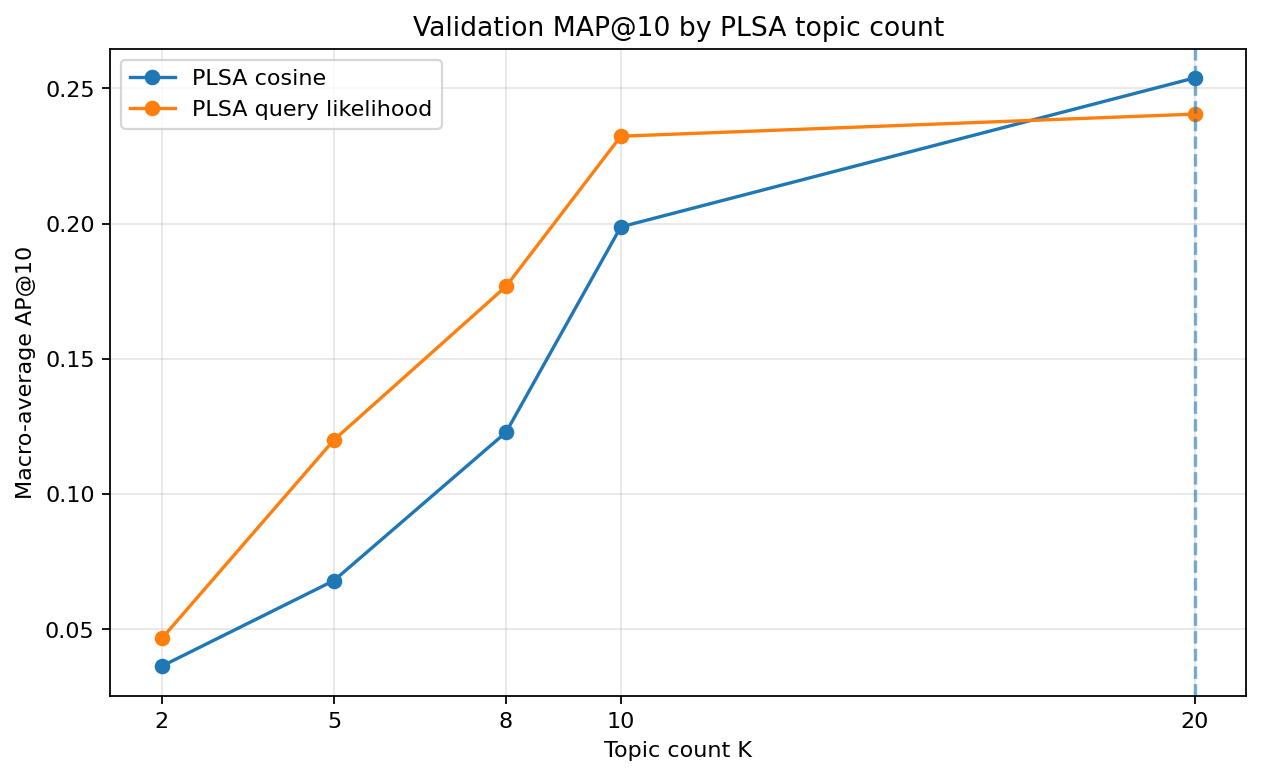

**Test curve:** compare the predeclared PLSA models with the fixed TF-IDF/LSI references.

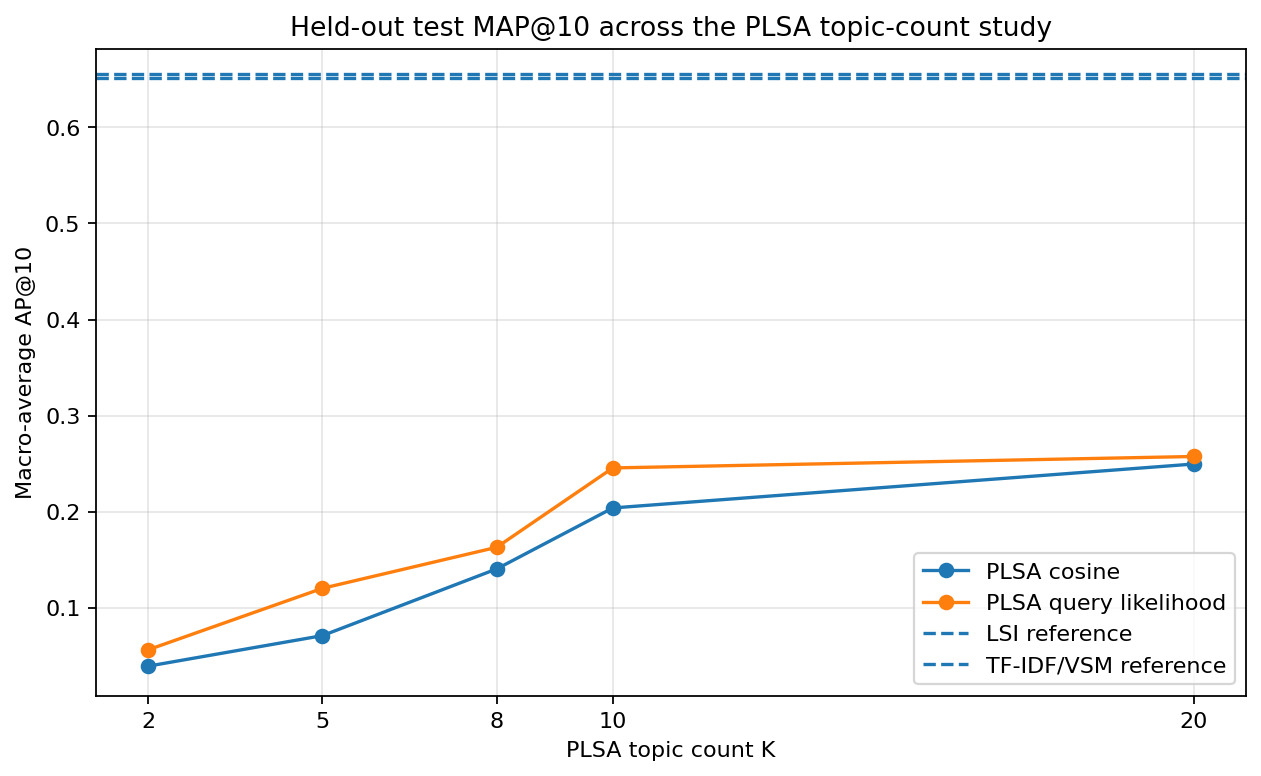

### Per-category PLSA AP@10 across K

The pivot contains PLSA columns; fixed baselines with blank K are available in test_metrics_by_query.csv.

In [4]:
# EXPERIMENT 03: keep validation selection separate from test reporting.
folder = 'all20_k_study'
settings = context(folder, '03_all20_k_study.ipynb')
validation = read_table(folder, 'validation_plsa_summary.csv')
selected = read_table(folder, 'test_metrics_at_validation_selected_k.csv')
all_test = read_table(folder, 'test_metrics_summary.csv')
check_macro(read_table(folder, 'test_metrics_by_query.csv'), all_test, groups=('K', 'method'),
            description='03: each test K/method summary matches its query scores')
check_macro(read_table(folder, 'validation_metrics_by_query.csv'), validation, groups=('K', 'method'),
            description='03: validation summaries match query scores')
chosen = {method: int(group.sort_values(['MAP@10', 'Precision@10'], ascending=False).iloc[0]['K'])
          for method, group in validation.groupby('method')}
assert chosen == settings['validation_selected_k'], 'Selected K differs from saved configuration.'
CHECKS.append('03: selected K matches validation ranking and configuration')
# Independently reconstruct which test rows should appear at validation-selected K.
expected_selected = all_test.loc[all_test.apply(
    lambda row: not row['method'].startswith('PLSA') or row['K'] == chosen[row['method']], axis=1)]
left = expected_selected.set_index('method').sort_index()
right = selected.set_index('method').sort_index()
pd.testing.assert_index_equal(left.index, right.index)
check_close(left, right[left.columns], '03: selected test rows use only validation-selected K')
TABLES['03'] = selected
show_table(pd.DataFrame(list(chosen.items()), columns=['method', 'selected_K']),
           'Settings selected on validation', 'Selection is based only on validation results.')
show_table(selected, 'Held-out test at the selected K', 'A blank K for TF-IDF/LSI means PLSA topic count is not applicable.')
finding(selected)
show_table(validation, 'Validation sensitivity to K', 'Mean AP across 20 validation queries is MAP@10.')
show_table(all_test, 'All predeclared test K values and fixed references', 'This full curve describes sensitivity, not a second tuning step.')
show_plot(folder, 'validation_map_by_k.png', '**Validation curve:** used to select K independently for each scoring rule.')
show_plot(folder, 'test_map_by_k.png', '**Test curve:** compare the predeclared PLSA models with the fixed TF-IDF/LSI references.')
# Read this pivot with TWO header rows so K and method remain separate levels.
show_table(read_table(folder, 'test_ap_by_query.csv'), 'Per-category PLSA AP@10 across K',
           'The pivot contains PLSA columns; fixed baselines with blank K are available in test_metrics_by_query.csv.')
output_catalog(folder)

<a id="experiment-04"></a>
## 04 — Retrieval scoring investigation

This is the **six-original-category subset** (5,829 documents), a 75/25 split,
K=6 and five restarts. It asks whether two scoring rules rank documents
differently **using the same fitted PLSA model**. TF-IDF and LSI are reference
methods on the same non-empty test candidates and six fixed queries.

**How generated:** fold queries/documents into topics for cosine scoring;
for likelihood, sum query counts times log of the document's PLSA word
probabilities. There is no background mixture; a `1e-10` floor avoids log(0).
The overlap table counts the intersection of the two top-10 document sets
(and divides by 10). Spearman correlation compares their full score rankings.
The per-query difference is `AP_likelihood - AP_cosine`; a positive value
favours query likelihood. Agreement measures similarity of rankings, not
relevance quality, so read them alongside the retrieval scores.

**Source:** `experiments/04_retrieval_scoring_investigation.ipynb`  
**Saved outputs:** `results/retrieval_scoring_investigation/`

### Retrieval by scoring rule

Mean metrics across six queries; higher values are better.

method,Precision@10,Recall@10,MAP@10,NDCG@10
TF-IDF/VSM,0.9667,0.0410,0.9451,0.9716
LSI,0.9333,0.0397,0.9112,0.9480
PLSA cosine,0.8333,0.0352,0.6885,0.7877
PLSA query likelihood,0.8667,0.0366,0.7879,0.8587


**Observed in this saved run:** TF-IDF/VSM has the highest MAP@10 in this table (0.9451). This is a comparison on the stated fixed query set, not a universal ranking of methods.

### Which queries benefit from likelihood?

Positive differences favour likelihood; negative values favour cosine.

query_category,PLSA cosine,PLSA query likelihood,query_likelihood_minus_cosine_AP@10
comp.graphics,0.7571,1.0000,0.2429
misc.forsale,0.8354,1.0000,0.1646
rec.sport.baseball,1.0000,1.0000,0.0000
sci.med,0.7071,0.8354,0.1283
sci.space,0.6378,0.6711,0.0333
talk.politics.guns,0.1938,0.2206,0.0268


### Ranking agreement

Overlap concerns the top ten document IDs; Spearman correlation concerns the full rankings.

query_category,top10_overlap_count,top10_overlap_fraction,spearman_rank_correlation
comp.graphics,3,0.3000,0.9065
misc.forsale,5,0.5000,0.9321
rec.sport.baseball,2,0.2000,0.8748
sci.med,10,1.0000,0.8659
sci.space,9,0.9000,0.8615
talk.politics.guns,7,0.7000,0.9161


**Retrieval quality:** metric averages for each method/scoring rule.

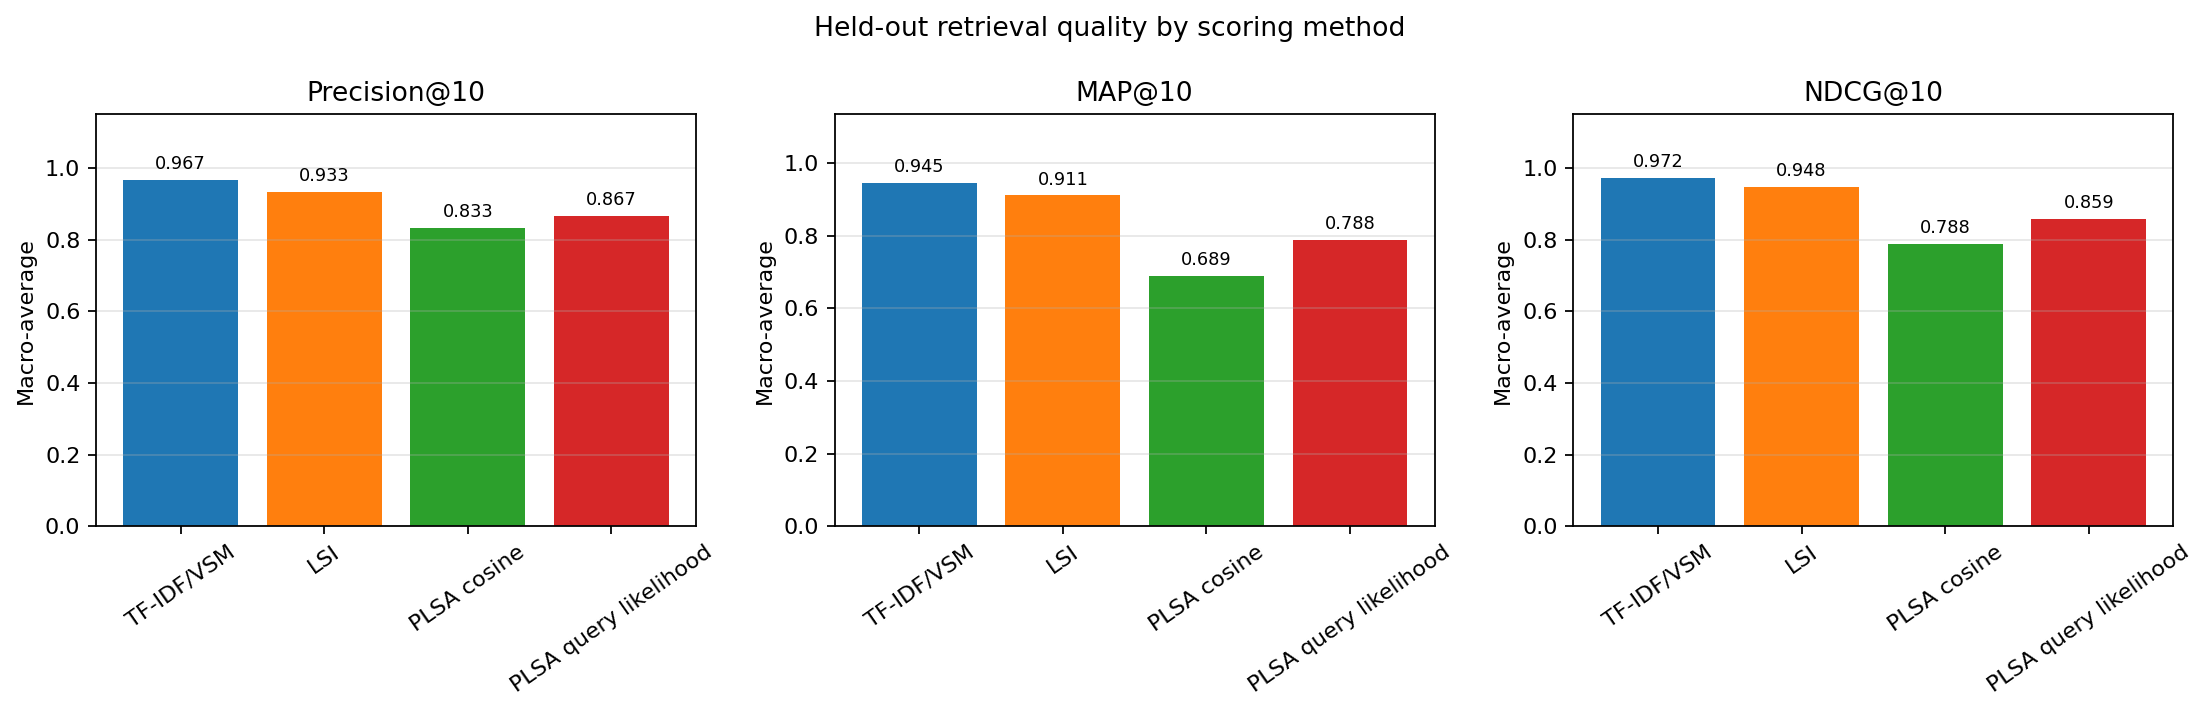

**Top-10 overlap:** lower overlap means the scorers retrieve different documents.

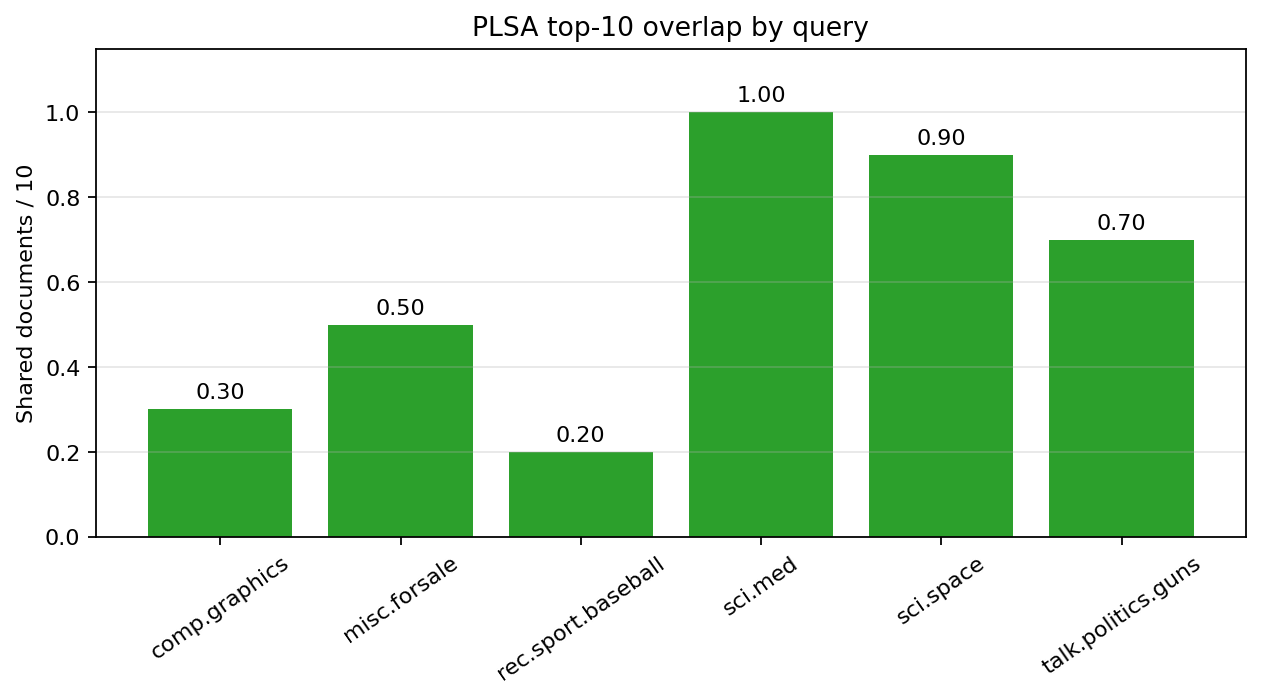

In [5]:
# EXPERIMENT 04: compare scoring rules while the learned PLSA parameters stay fixed.
folder = 'retrieval_scoring_investigation'
settings = context(folder, '04_retrieval_scoring_investigation.ipynb')
summary = read_table(folder, 'retrieval_metrics_macro_average.csv')
check_macro(read_table(folder, 'retrieval_metrics_by_query.csv'), summary,
            description='04: macro metrics match six-query scoring table')
TABLES['04'] = summary
show_table(summary, 'Retrieval by scoring rule', 'Mean metrics across six queries; higher values are better.')
finding(summary)
difference = read_table(folder, 'plsa_ap_difference_by_query.csv')
check_close(difference['PLSA query likelihood'] - difference['PLSA cosine'],
            difference['query_likelihood_minus_cosine_AP@10'], '04: saved AP differences are correct')
show_table(difference, 'Which queries benefit from likelihood?', 'Positive differences favour likelihood; negative values favour cosine.')
show_table(read_table(folder, 'plsa_scoring_agreement_by_query.csv'), 'Ranking agreement',
           'Overlap concerns the top ten document IDs; Spearman correlation concerns the full rankings.')
show_plot(folder, 'retrieval_metrics_comparison.png', '**Retrieval quality:** metric averages for each method/scoring rule.')
show_plot(folder, 'plsa_top10_overlap.png', '**Top-10 overlap:** lower overlap means the scorers retrieve different documents.')
output_catalog(folder)

<a id="experiment-05"></a>
## 05 — Validation and query study

Use the six-category subset with a 60/20/20 split and **18 queries**: direct,
paraphrase and related-term variants for each category. Fit PLSA at K in
`{3, 6, 10, 20}`, taking the best of three restarts per K. Cosine is tuned over
K; likelihood is tuned over K and background weights `{0, 0.01, 0.05}`.
The unigram background is computed from training counts only.

**How generated:** choose maximum validation MAP@10, then Precision@10, then
smaller K and (for likelihood) smaller background weight. Freeze those choices
and score test queries once per selected method. The query-family table
averages six queries per family; the overall table averages all 18. Vocabulary
coverage is the fraction of **unique processed query terms** present in the
training count vocabulary. It is diagnostic, not a relevance metric.

Training resources time all three restarts for each K; inference resources time
test fold-in for the selected model. RSS is sampled for the **whole process**,
with MiB-sized units labeled MB by the source, so it is not isolated model
memory. These measurements describe the teammate's run environment, not this
report's rendering time.

**Source:** `experiments/05_retrieval_validation_query_study.ipynb`  
**Saved outputs:** `results/retrieval_validation_query_study/`

### Validation-selected settings

Blank background weight means it is not used by cosine scoring.

method,selected_K,background_weight
PLSA cosine,20,NaN
PLSA query likelihood,20,0.0000


### Held-out test — all 18 queries

Settings were fixed using validation before these scores were evaluated.

method,Precision@10,Recall@10,MAP@10,NDCG@10
TF-IDF/VSM,0.9278,0.0492,0.9063,0.9422
LSI,0.9389,0.0497,0.9125,0.9490
PLSA cosine,0.9556,0.0506,0.9052,0.9452
PLSA query likelihood,0.9500,0.0503,0.8930,0.9372


**Observed in this saved run:** LSI has the highest MAP@10 in this table (0.9125). This is a comparison on the stated fixed query set, not a universal ranking of methods.

... (9 outputs left out)

K,selected_iterations,best_training_log_likelihood,runtime_seconds,memory_before_MB,memory_after_MB,peak_process_memory_MB,peak_increase_from_start_MB
3,53,-1535921.7809,4.0140,166.5400,178.0000,199.0500,32.5200
6,49,-1487732.1323,6.4550,178.2000,180.1100,220.5100,42.3000
10,54,-1454055.3611,11.1040,180.1100,183.9100,247.6200,67.5100
20,76,-1414907.5242,25.0740,183.9200,188.4300,313.5000,129.5800


### Test fold-in runtime and process memory

These are saved measurements of the selected models, not newly measured timings.

operation,K,runtime_seconds,memory_before_MB,memory_after_MB,peak_process_memory_MB,peak_increase_from_start_MB
Fold in test documents for validation-selected PLSA cosine model,20,1.6300,375.7200,375.8600,375.8600,0.1400
Fold in test documents for validation-selected PLSA query-likelihood model,20,1.6110,375.8600,376.0700,376.0800,0.2200


**Validation tuning:** compare K and the likelihood background weight before using test results.

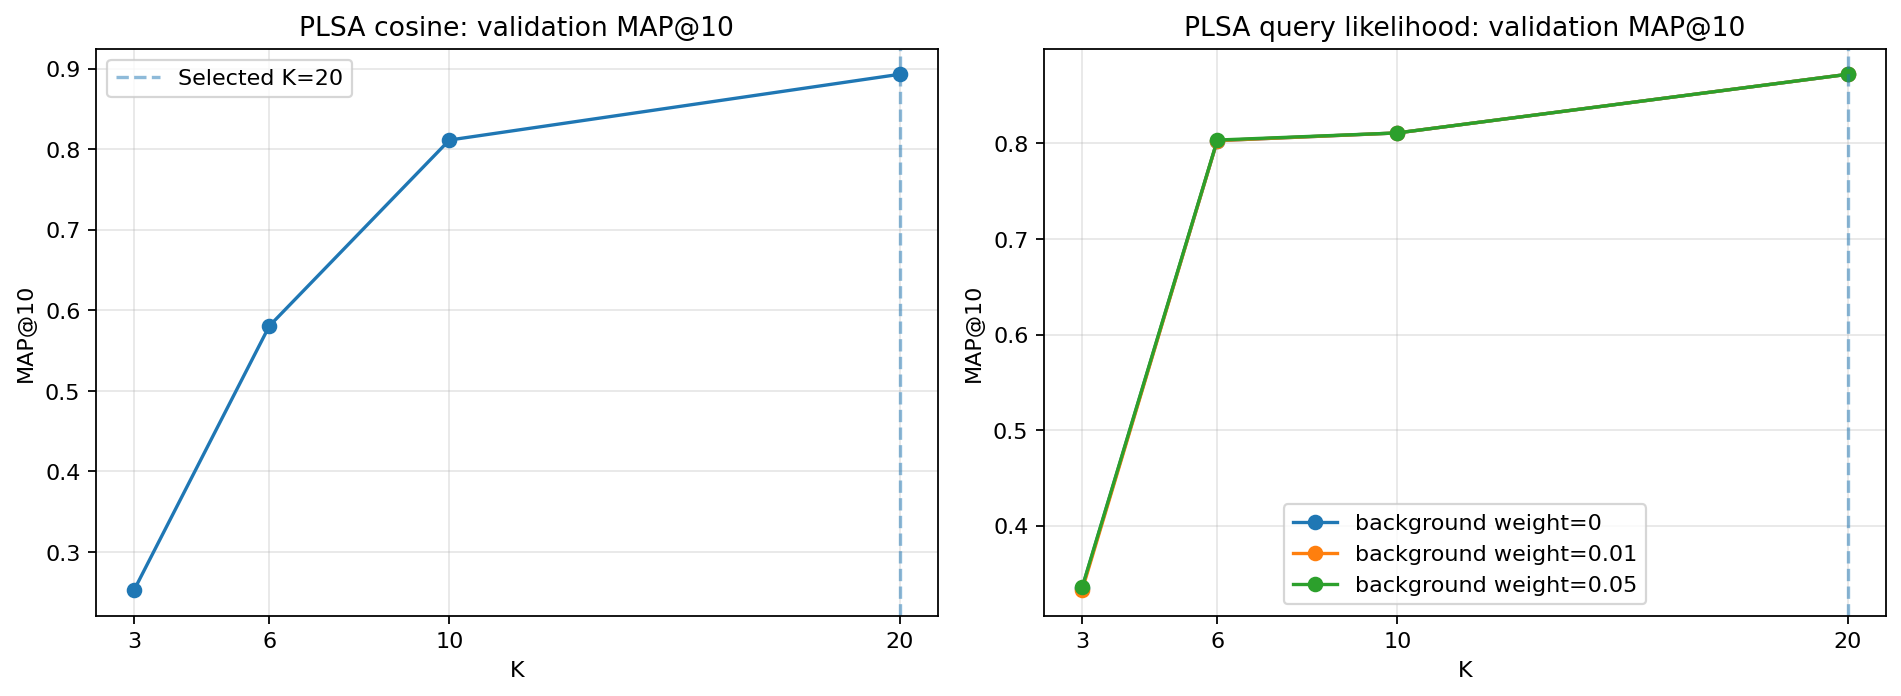

**Held-out query families:** direct, paraphrase and related-term retrieval.

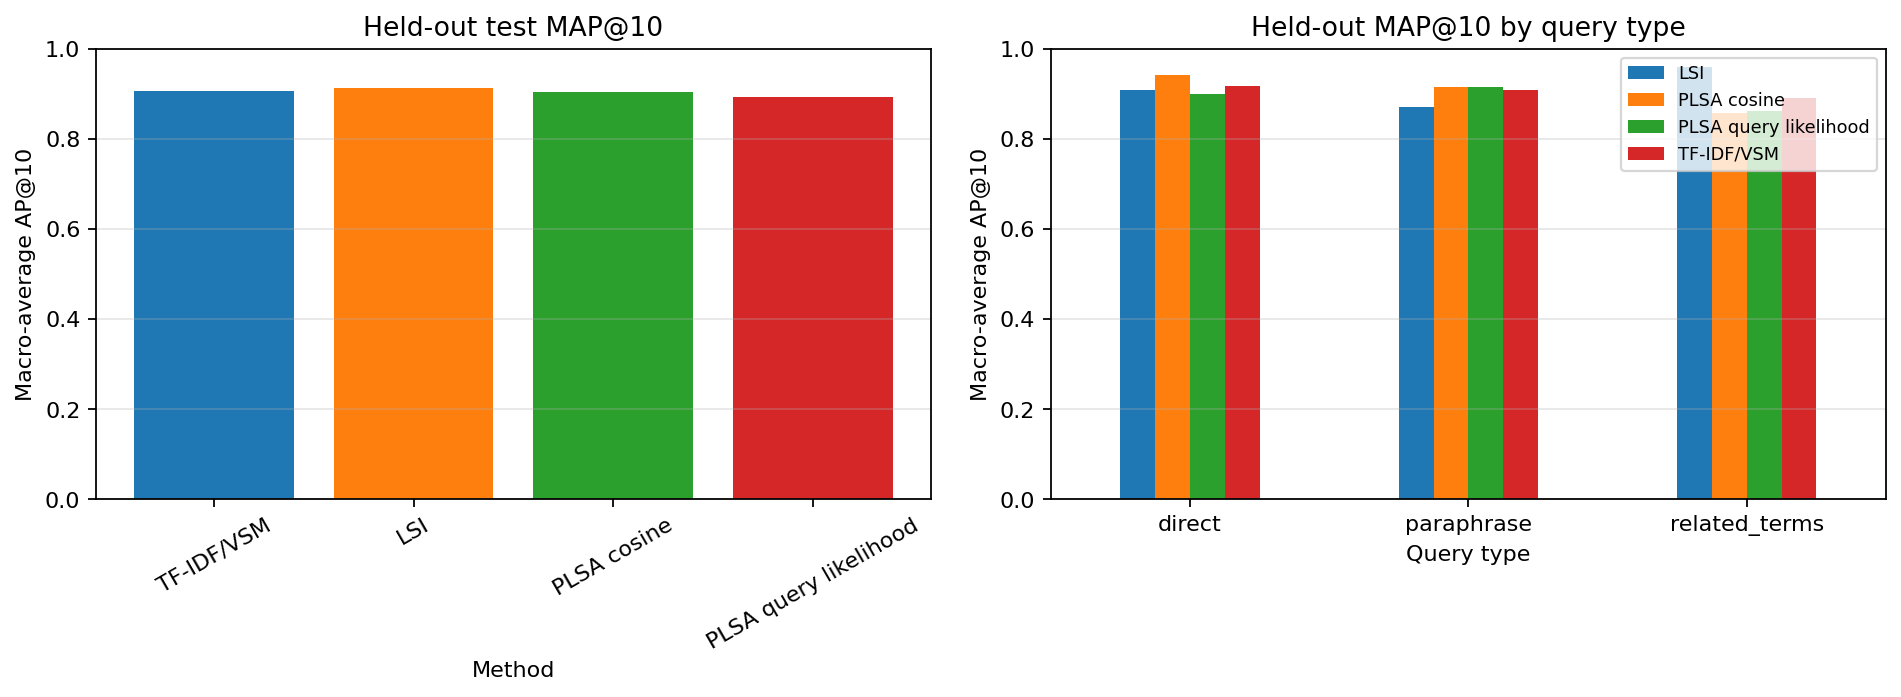

In [6]:
# EXPERIMENT 05: present validation tuning, frozen-setting test scores and diagnostics.
folder = 'retrieval_validation_query_study'
settings = context(folder, '05_retrieval_validation_query_study.ipynb')
cosine = read_table(folder, 'validation_plsa_cosine_tuning.csv')
likelihood = read_table(folder, 'validation_plsa_query_likelihood_tuning.csv')
best_cos = cosine.sort_values(['MAP@10', 'Precision@10', 'K'], ascending=[False, False, True]).iloc[0]
best_ll = likelihood.sort_values(['MAP@10', 'Precision@10', 'K', 'background_weight'],
                                ascending=[False, False, True, True]).iloc[0]
assert int(best_cos['K']) == settings['validation_selected_plsa_cosine']['K']
assert int(best_ll['K']) == settings['validation_selected_plsa_query_likelihood']['K']
assert float(best_ll['background_weight']) == settings['validation_selected_plsa_query_likelihood']['background_weight']
CHECKS.append('05: selected K/background settings match the validation tables')
selected_settings = pd.DataFrame([
    {'method': 'PLSA cosine', 'selected_K': int(best_cos['K']), 'background_weight': np.nan},
    {'method': 'PLSA query likelihood', 'selected_K': int(best_ll['K']), 'background_weight': best_ll['background_weight']},
])
show_table(selected_settings, 'Validation-selected settings', 'Blank background weight means it is not used by cosine scoring.')
summary = read_table(folder, 'test_metrics_macro_average.csv')
raw = read_table(folder, 'test_metrics_by_query.csv')
check_macro(raw, summary, description='05: test macro metrics match the 18-query table')
family = read_table(folder, 'test_metrics_by_query_type.csv')
check_macro(raw, family, groups=('query_type', 'method'), description='05: query-family means match test query scores')
TABLES['05'] = summary
show_table(summary, 'Held-out test — all 18 queries', 'Settings were fixed using validation before these scores were evaluated.')
finding(summary)
show_table(family, 'Results by query wording', 'Each query family contains six category queries; averages expose differences hidden by the overall table.')
show_table(cosine, 'Cosine validation grid', 'K selection uses validation MAP@10.')
show_table(likelihood, 'Likelihood validation grid', 'K and background weight selection uses validation MAP@10 and the documented tie-breaks.')
show_table(read_table(folder, 'query_vocabulary_coverage.csv'), 'Query coverage in the training vocabulary',
           'Counts refer to unique processed terms. OOV = out of vocabulary; zero coverage leaves no known query terms.')
show_table(read_table(folder, 'plsa_training_resources.csv'), 'Training runtime and process memory',
           'Runtime wraps all three restarts at the displayed K. Peak memory includes the rest of the Python process.')
show_table(read_table(folder, 'plsa_inference_resources.csv'), 'Test fold-in runtime and process memory',
           'These are saved measurements of the selected models, not newly measured timings.')
show_plot(folder, 'validation_tuning_map.png', '**Validation tuning:** compare K and the likelihood background weight before using test results.')
show_plot(folder, 'test_retrieval_by_query_type.png', '**Held-out query families:** direct, paraphrase and related-term retrieval.')
output_catalog(folder)

<a id="experiment-06"></a>
## 06 — Bagging and restart ensembles

Retain all 20 categories mapped to the same six groups as experiment 02, using
its 80/20 split, K=6 and six queries. The full-data models use the complete
training partition. Five full-data PLSA initializations form both the best
single-restart reference and a restart ensemble. Five bootstrap samples draw
15,076 rows each **with replacement**; PLSA, TF-IDF and LSI reuse the same
sampled row indices for a matched ensemble comparison.

**How generated:** each member ranks the same eligible test documents. Convert
scores to zero-based ranks and average ranks across members; the negative mean
rank is the combined score (larger is better). Re-evaluate the combined ranking
against the group labels, then average the six query metrics. This is **not**
an average of member MAP values. Bootstrap members refit the relevant model
representations; the PLSA members share the count vocabulary.

The sampling table explains why sampled rows exceed unique documents. Training
likelihoods on different bootstrap matrices should not be ranked as if they
were computed on the same data. Gains here concern this fixed six-query task;
no significance test or general superiority claim is implied.

**Source:** `experiments/06_bagging_experiment.ipynb`  
**Saved outputs:** `results/bagging_experiment/`

### Full-data and ensemble retrieval

Each row evaluates the final ranking of one method; all methods share queries and test candidates.

method,Precision@10,Recall@10,MAP@10,NDCG@10
TF-IDF/VSM (full),0.8833,0.0166,0.8189,0.8982
LSI (full),0.8333,0.0167,0.7155,0.8077
PLSA cosine (best restart),0.4333,0.0068,0.2858,0.4248
PLSA query likelihood (best restart),0.4833,0.0079,0.3567,0.4892
PLSA cosine (5 restarts),0.9167,0.0170,0.8845,0.9356
PLSA query likelihood (5 restarts),0.9000,0.0168,0.8260,0.8937
PLSA cosine (bagged),0.9500,0.0185,0.9196,0.9505
PLSA query likelihood (bagged),0.9333,0.0181,0.9137,0.9491
TF-IDF/VSM (bagged),0.8833,0.0166,0.8220,0.8990
LSI (bagged),0.8167,0.0163,0.6869,0.7988


**Observed in this saved run:** PLSA cosine (bagged) has the highest MAP@10 in this table (0.9196). This is a comparison on the stated fixed query set, not a universal ranking of methods.

### Derived ensemble-minus-reference comparison

Positive values mean higher MAP for the ensemble on these saved queries; differences are in score units, not percent.

ensemble,reference,MAP@10 difference
TF-IDF/VSM (bagged),TF-IDF/VSM (full),0.0031
LSI (bagged),LSI (full),-0.0286
PLSA cosine (5 restarts),PLSA cosine (best restart),0.5987
PLSA cosine (bagged),PLSA cosine (best restart),0.6338
PLSA query likelihood (5 restarts),PLSA query likelihood (best restart),0.4693
PLSA query likelihood (bagged),PLSA query likelihood (best restart),0.5571


... (5 outputs left out)

member,unique_training_documents,iterations,bootstrap_training_log_likelihood
1,9477,50,-6278146.0613
2,9516,49,-6216022.2690
3,9493,61,-5967843.1224
4,9505,42,-6099398.2392
5,9605,53,-6069677.5826


### TF-IDF / LSI bootstrap members

The feature count and LSI dimensions belong to each independently fitted bootstrap baseline.

member,bootstrap_rows,tfidf_features,lsi_dimensions
1,15076,3000,50
2,15076,3000,50
3,15076,3000,50
4,15076,3000,50
5,15076,3000,50


**Ensemble comparison:** metrics computed after combining member rankings.

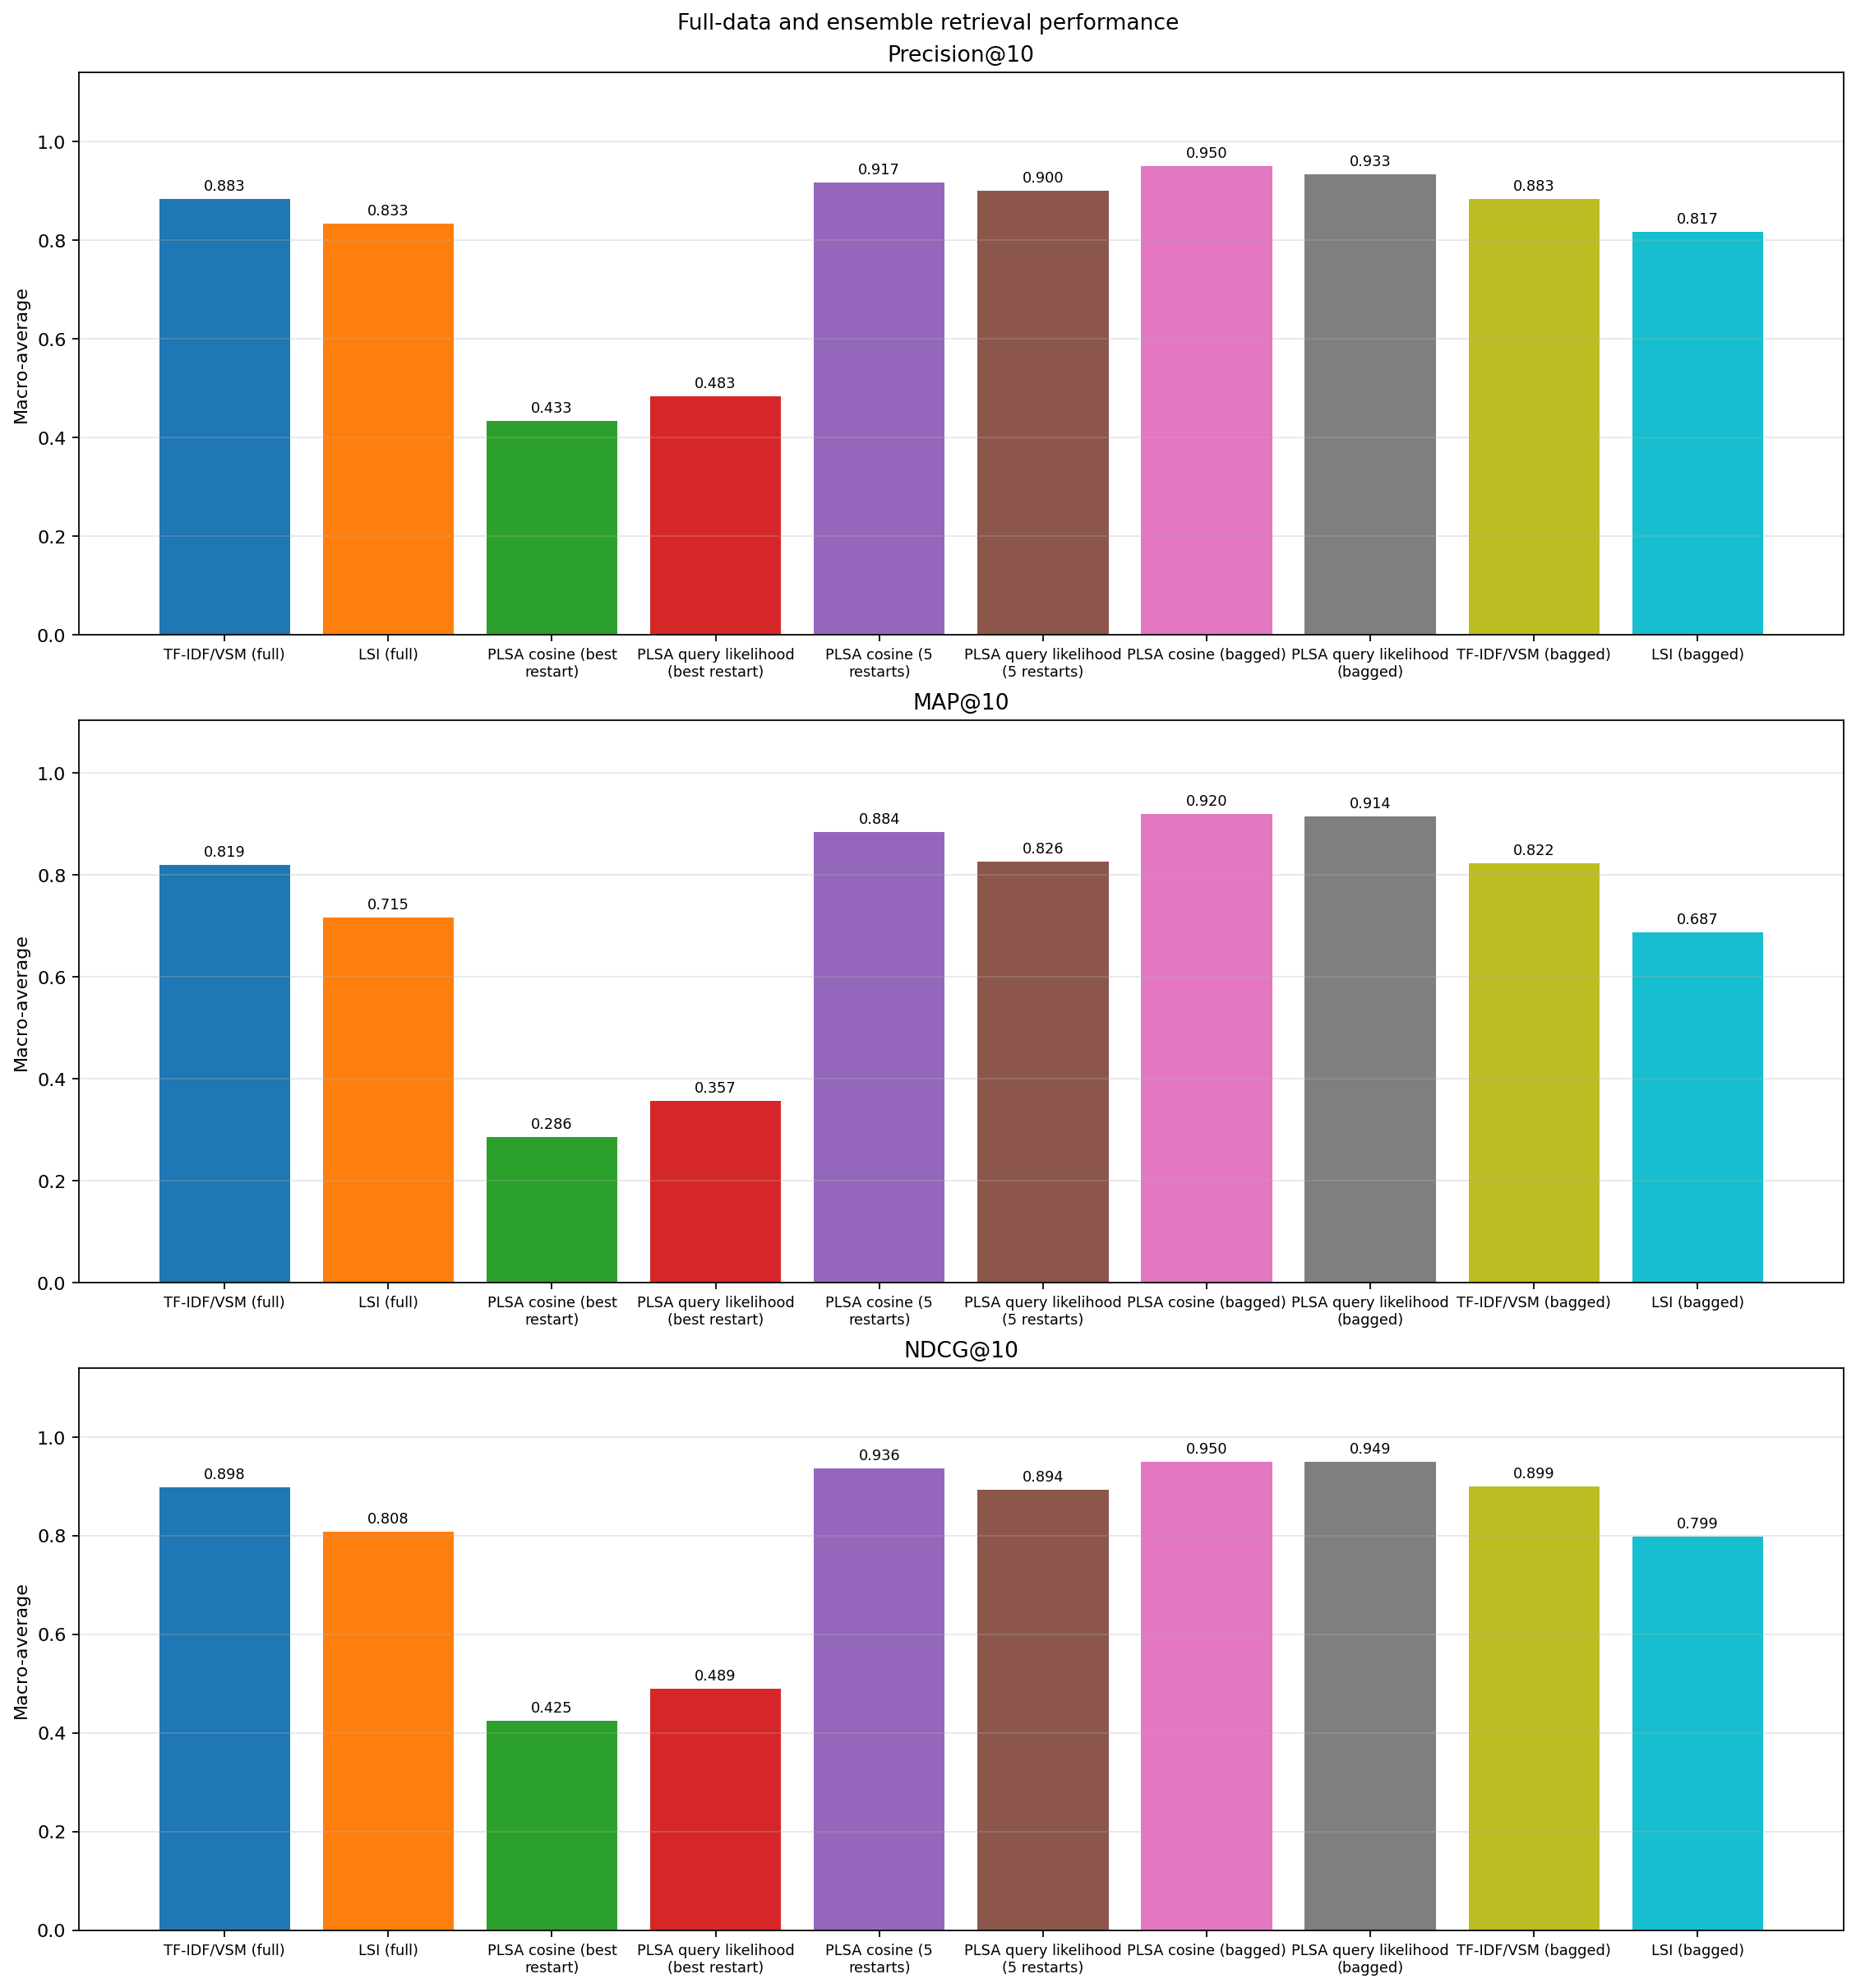

member,bootstrap_rows,tfidf_features,lsi_dimensions
1,15076,3000,50
2,15076,3000,50
3,15076,3000,50
4,15076,3000,50
5,15076,3000,50
member,sampled_rows,unique_training_documents,omitted_training_documents
1,15076,9477,5599
2,15076,9516,5560
3,15076,9493,5583
4,15076,9505,5571


In [7]:
# EXPERIMENT 06: compare the ten full-data, restart-ensemble and bagged methods.
folder = 'bagging_experiment'
settings = context(folder, '06_bagging_experiment.ipynb')
summary = read_table(folder, 'retrieval_metrics_macro_average.csv')
check_macro(read_table(folder, 'retrieval_metrics_by_query.csv'), summary,
            description='06: ten-method macro metrics match the six-query table')
TABLES['06'] = summary
show_table(summary, 'Full-data and ensemble retrieval', 'Each row evaluates the final ranking of one method; all methods share queries and test candidates.')
finding(summary)
# Derived comparison: subtract the matching full-data reference from its ensemble.
by_method = summary.set_index('method')
pairs = [
    ('TF-IDF/VSM (bagged)', 'TF-IDF/VSM (full)'),
    ('LSI (bagged)', 'LSI (full)'),
    ('PLSA cosine (5 restarts)', 'PLSA cosine (best restart)'),
    ('PLSA cosine (bagged)', 'PLSA cosine (best restart)'),
    ('PLSA query likelihood (5 restarts)', 'PLSA query likelihood (best restart)'),
    ('PLSA query likelihood (bagged)', 'PLSA query likelihood (best restart)'),
]
deltas = pd.DataFrame([{'ensemble': ensemble, 'reference': reference,
                       'MAP@10 difference': by_method.loc[ensemble, 'MAP@10'] - by_method.loc[reference, 'MAP@10']}
                      for ensemble, reference in pairs])
show_table(deltas, 'Derived ensemble-minus-reference comparison',
           'Positive values mean higher MAP for the ensemble on these saved queries; differences are in score units, not percent.')
show_table(read_table(folder, 'bootstrap_sampling_summary.csv'), 'Bootstrap sampling',
           'Repeated rows are expected when drawing a training-size sample with replacement.')
show_table(read_table(folder, 'plsa_full_data_restart_summary.csv'), 'Full-data PLSA restart control',
           'The single reference is selected by full-training log-likelihood; all five fits contribute to the restart ensemble.')
show_table(read_table(folder, 'plsa_bootstrap_member_summary.csv'), 'PLSA bootstrap members',
           'Each row describes a different sampled training matrix.')
show_table(read_table(folder, 'baseline_bootstrap_member_summary.csv'), 'TF-IDF / LSI bootstrap members',
           'The feature count and LSI dimensions belong to each independently fitted bootstrap baseline.')
show_plot(folder, 'retrieval_ensemble_comparison.png', '**Ensemble comparison:** metrics computed after combining member rankings.')
output_catalog(folder)

<a id="experiment-07"></a>
## 07 — Topic-mixture and boundary experiment

This is a **PLSA probability probe**, not a retrieval leaderboard. Use all
20 categories and the baseline's 75/25 split, K=5; the held-out partition is
unused. Compare the best full-data restart, the five-restart ensemble, and
five bootstrap models trained from the training partition.

**How generated:** for each model separately, use non-empty training documents
to find the topic with the highest mean probability for baseball (source A)
and `talk.politics.misc` (source B). Topic IDs are not shared across models.
Generate 300-token mixtures at A ratios `{0, .1, .3, .5, .7, .9, 1}`, with 30
replicates at each ratio. Every model receives the same synthetic documents.
Fold in each mixture, extract that model's two associated topic probabilities,
and average **aligned probabilities** across members within each replicate.
Finally compute the mean and sample standard deviation over replicates.

Thus the saved tables have 2,310 member-level rows (210 mixtures × 11 model
entries), 630 family/replicate rows, and 21 family/ratio summaries. The baseline
entry is also one of the five full-data restarts; these are not 11 independent
fits. Unlike experiment 06, this ensemble averages probabilities, not ranks.

**Interpretation:** the two displayed topic probabilities need not sum to one,
and a known source-token proportion is not a true topic probability. Error bars
show between-mixture standard deviation after member averaging, not confidence
intervals. If both source categories select the same topic for a member, that
member cannot distinguish them via these two coordinates.

**Source:** `experiments/07_topic_boundary_experiment.ipynb`  
**Saved outputs:** `results/topic_boundary_experiment/`

### Aggregation stages

Member probabilities → aligned within-replicate means → across-replicate mean/std.

level,saved_rows
Member-level,2310
Family / replicate,630
Family / ratio,21


### Source-mixture probability responses

Each row summarizes 30 generated documents for one family and source ratio.

model_family,sampled_source_a_token_ratio,sampled_source_b_token_ratio,source_a_topic_mean,source_a_topic_std,source_b_topic_mean,source_b_topic_std
PLSA baseline (best full-data restart),0.0000,1.0000,0.1411,0.2061,0.4408,0.3286
PLSA baseline (best full-data restart),0.1000,0.9000,0.2045,0.1345,0.3198,0.2014
PLSA baseline (best full-data restart),0.3000,0.7000,0.3227,0.1951,0.3651,0.2473
PLSA baseline (best full-data restart),0.5000,0.5000,0.4194,0.1977,0.3092,0.2153
PLSA baseline (best full-data restart),0.7000,0.3000,0.5578,0.2326,0.2268,0.2189
PLSA baseline (best full-data restart),0.9000,0.1000,0.6955,0.1971,0.1560,0.1499
PLSA baseline (best full-data restart),1.0000,0.0000,0.6765,0.2727,0.1007,0.1342
PLSA bootstrap ensemble (5 members),0.0000,1.0000,0.2301,0.1594,0.3815,0.0678
PLSA bootstrap ensemble (5 members),0.1000,0.9000,0.2805,0.1202,0.3742,0.0617
PLSA bootstrap ensemble (5 members),0.3000,0.7000,0.3635,0.1421,0.3552,0.0662


### Within-model source-to-topic associations

Associations are selected separately inside each model using its own non-empty source training documents.

model_family,member,source_category,associated_topic,mean_probability_in_source_category,nonempty_source_training_documents
PLSA baseline (best full-data restart),best_restart,rec.sport.baseball,1,0.7287,698
PLSA baseline (best full-data restart),best_restart,talk.politics.misc,2,0.4144,561
PLSA full-data restart ensemble (5 members),restart_1,rec.sport.baseball,1,0.6704,698
PLSA full-data restart ensemble (5 members),restart_1,talk.politics.misc,3,0.3306,561
PLSA full-data restart ensemble (5 members),restart_2,rec.sport.baseball,4,0.7364,698
PLSA full-data restart ensemble (5 members),restart_2,talk.politics.misc,2,0.4634,561
PLSA full-data restart ensemble (5 members),restart_3,rec.sport.baseball,1,0.7287,698
PLSA full-data restart ensemble (5 members),restart_3,talk.politics.misc,2,0.4144,561
PLSA full-data restart ensemble (5 members),restart_4,rec.sport.baseball,1,0.5528,698
PLSA full-data restart ensemble (5 members),restart_4,talk.politics.misc,2,0.4202,561


### Members with the same topic for both sources

These source coordinates coincide; interpret their probabilities cautiously.

,source_category,rec.sport.baseball,talk.politics.misc
model_family,member,,
PLSA bootstrap ensemble (5 members),bootstrap_4,0,0


**Topic-mixture response:** original two-panel plot, with standard-deviation error bars and ideal-reference diagonals.

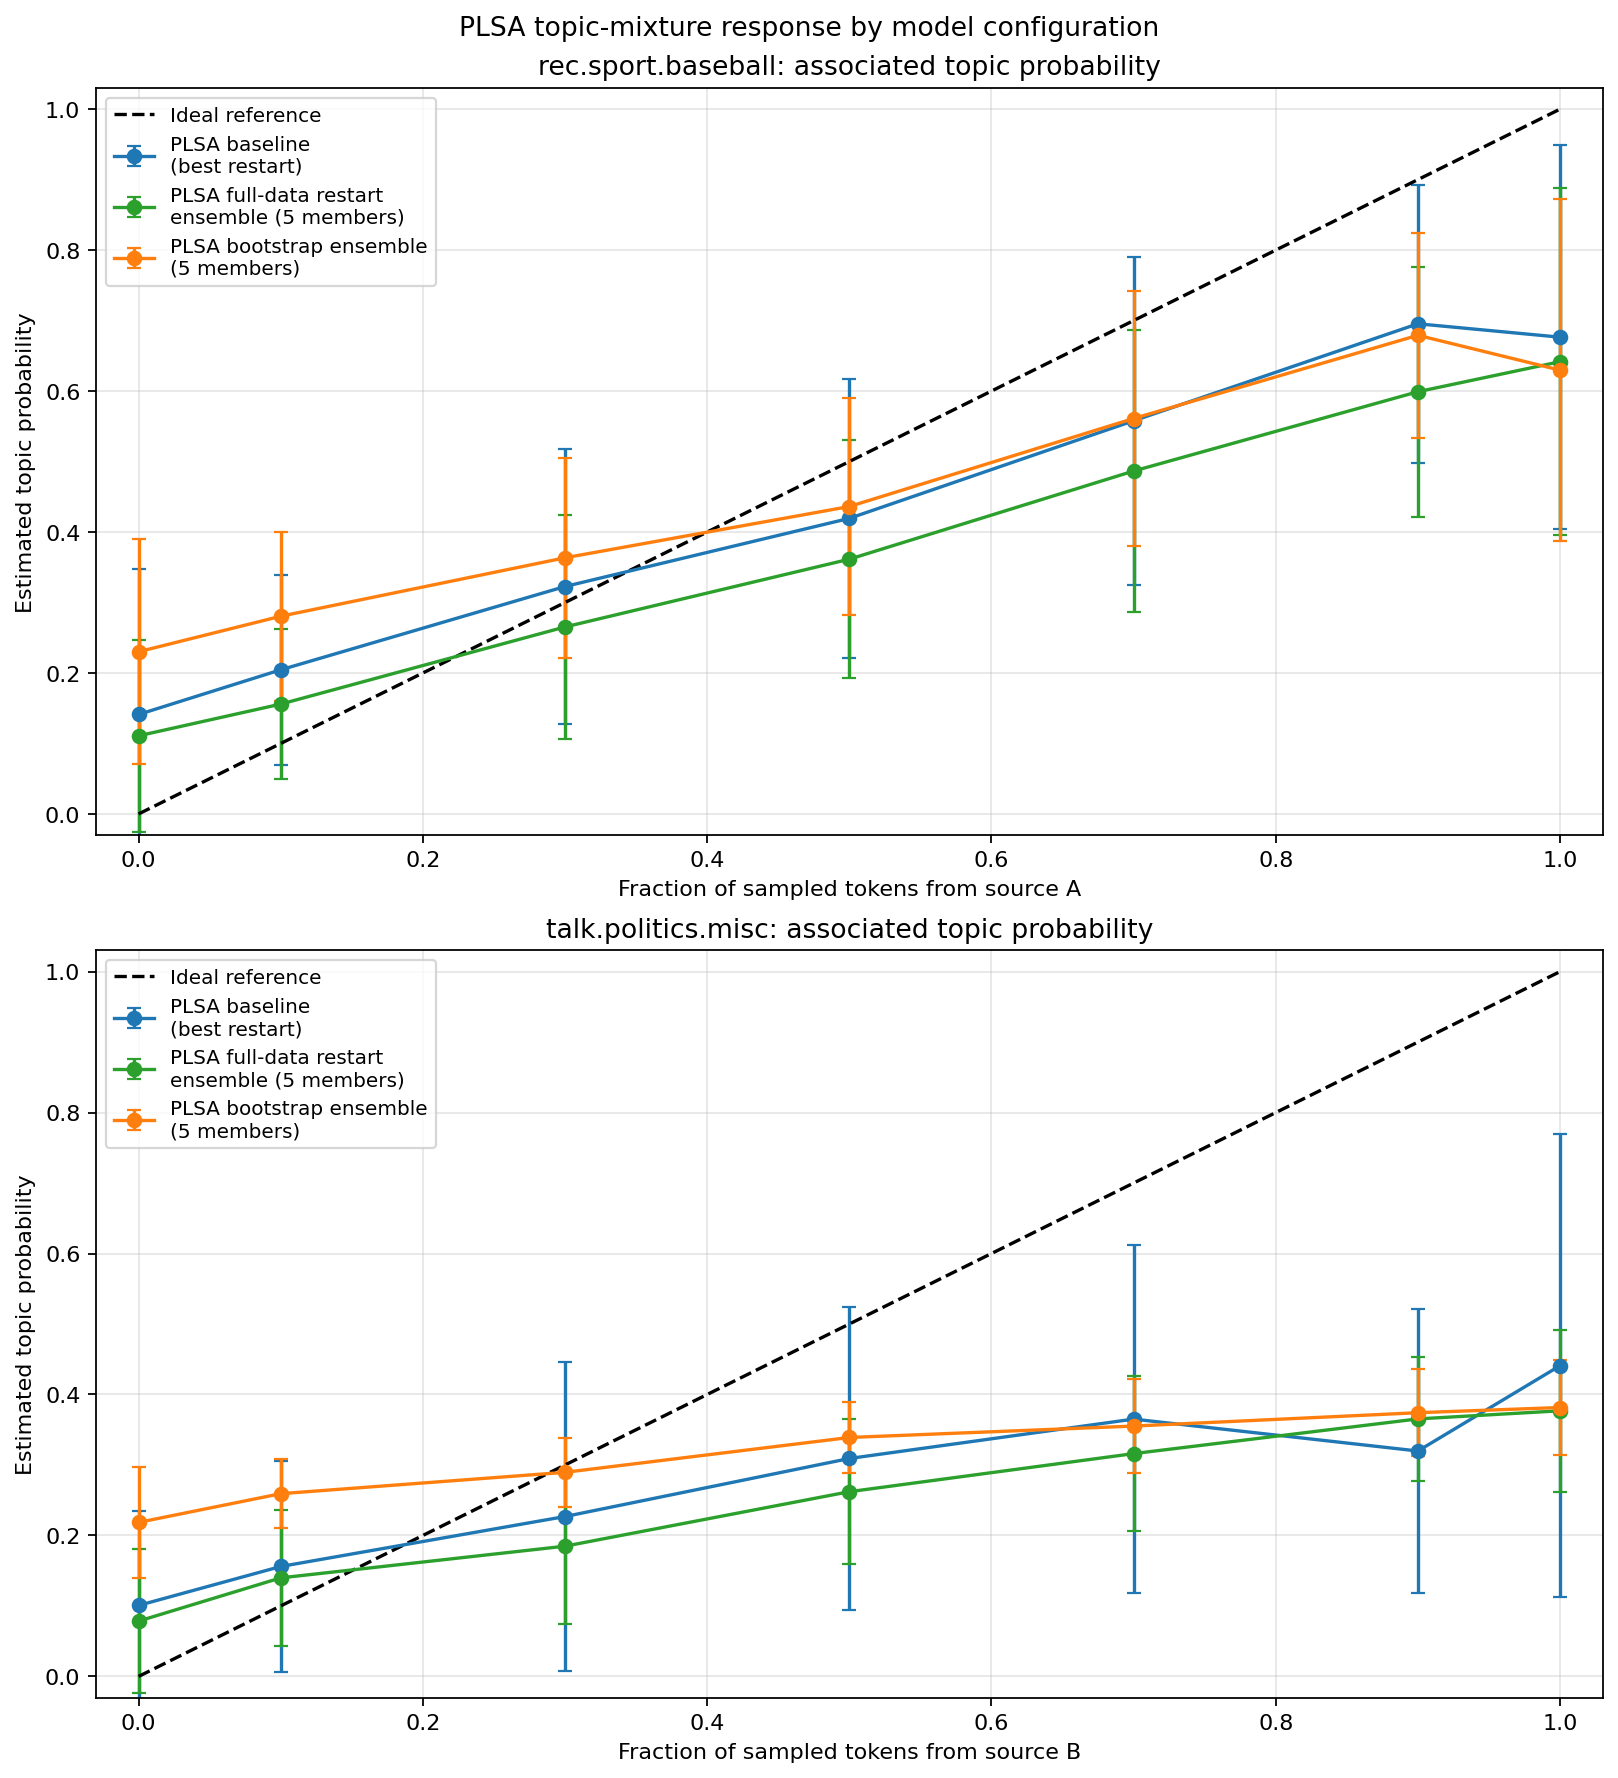

### Full-data restart fits

Best-restart baseline and the five members used for probability aggregation.

restart,seed,iterations,training_log_likelihood,is_baseline_best_restart
1,42,43,-5995748.4339,False
2,43,50,-5993380.3811,False
3,44,51,-5989043.2263,True
4,45,48,-6003355.0635,False
5,46,54,-5995924.9014,False


### Bootstrap fits

Row counts, unique training documents and training fit for each resample.

member,sampled_rows,unique_training_documents,iterations,bootstrap_training_log_likelihood
1,14134,8921,35,-6063509.5166
2,14134,8943,44,-6084545.0892
3,14134,8899,42,-5968923.1919
4,14134,8925,36,-6198530.5401
5,14134,8930,47,-5830869.9664


model_family,member,sampled_source_a_token_ratio,sampled_source_b_token_ratio,replicate,estimated_source_a_topic_probability,estimated_source_b_topic_probability
PLSA baseline (best full-data restart),best_restart,0.0000,1.0000,1,0.2384,0.3032
PLSA full-data restart ensemble (5 members),restart_1,0.0000,1.0000,1,0.0000,0.2436
PLSA full-data restart ensemble (5 members),restart_2,0.0000,1.0000,1,0.0631,0.4870
PLSA full-data restart ensemble (5 members),restart_3,0.0000,1.0000,1,0.2384,0.3032
PLSA full-data restart ensemble (5 members),restart_4,0.0000,1.0000,1,0.0835,0.0016
PLSA full-data restart ensemble (5 members),restart_5,0.0000,1.0000,1,0.0000,0.2411
PLSA bootstrap ensemble (5 members),bootstrap_1,0.0000,1.0000,1,0.1065,0.3898
PLSA bootstrap ensemble (5 members),bootstrap_2,0.0000,1.0000,1,0.2718,0.3541
PLSA bootstrap ensemble (5 members),bootstrap_3,0.0000,1.0000,1,0.2340,0.0019
PLSA bootstrap ensemble (5 members),bootstrap_4,0.0000,1.0000,1,0.6243,0.6243


In [8]:
# EXPERIMENT 07: show topic probabilities, not retrieval metrics.
folder = 'topic_boundary_experiment'
settings = context(folder, '07_topic_boundary_experiment.ipynb')
member = read_table(folder, 'mixture_estimates_by_member.csv')
replicate = read_table(folder, 'mixture_estimates_by_replicate.csv')
summary = read_table(folder, 'mixture_estimates_by_ratio.csv')
# Reconstruct both averaging stages from the exported records.
keys = ['model_family', 'sampled_source_a_token_ratio', 'sampled_source_b_token_ratio']
probabilities = ['estimated_source_a_topic_probability', 'estimated_source_b_topic_probability']
recomputed_replicates = member.groupby(keys + ['replicate'], as_index=False)[probabilities].mean()
check_close(recomputed_replicates.sort_values(keys + ['replicate'])[probabilities],
            replicate.sort_values(keys + ['replicate'])[probabilities],
            '07: replicate probabilities equal averages of aligned member probabilities')
recomputed_summary = replicate.groupby(keys, as_index=False).agg(
    source_a_topic_mean=(probabilities[0], 'mean'), source_a_topic_std=(probabilities[0], 'std'),
    source_b_topic_mean=(probabilities[1], 'mean'), source_b_topic_std=(probabilities[1], 'std'))
columns = ['source_a_topic_mean', 'source_a_topic_std', 'source_b_topic_mean', 'source_b_topic_std']
check_close(recomputed_summary.sort_values(keys)[columns], summary.sort_values(keys)[columns],
            '07: ratio summaries equal replicate means and sample standard deviations')
show_table(pd.DataFrame({'level': ['Member-level', 'Family / replicate', 'Family / ratio'],
                        'saved_rows': [len(member), len(replicate), len(summary)]}),
           'Aggregation stages', 'Member probabilities → aligned within-replicate means → across-replicate mean/std.')
show_table(summary, 'Source-mixture probability responses', 'Each row summarizes 30 generated documents for one family and source ratio.')
associations = read_table(folder, 'source_associated_topics.csv')
show_table(associations, 'Within-model source-to-topic associations',
           'Associations are selected separately inside each model using its own non-empty source training documents.')
# Flag any ambiguous mapping instead of assuming two distinct source topics.
association_pivot = associations.pivot(index=['model_family', 'member'], columns='source_category', values='associated_topic')
a, b = settings['source_categories']
collisions = association_pivot[association_pivot[a] == association_pivot[b]]
if collisions.empty:
    display(Markdown('**Association check:** the saved members map the two sources to distinct topics.'))
else:
    show_table(collisions, 'Members with the same topic for both sources', 'These source coordinates coincide; interpret their probabilities cautiously.')
show_plot(folder, 'topic_boundary_mixture_probabilities.png',
          '**Topic-mixture response:** original two-panel plot, with standard-deviation error bars and ideal-reference diagonals.')
show_table(read_table(folder, 'plsa_restart_summary.csv'), 'Full-data restart fits', 'Best-restart baseline and the five members used for probability aggregation.')
show_table(read_table(folder, 'plsa_bootstrap_member_summary.csv'), 'Bootstrap fits', 'Row counts, unique training documents and training fit for each resample.')
output_catalog(folder)

## Report checks and data provenance

The next cell lists the arithmetic checks performed by the seven result cells.
It also fingerprints all displayed/cataloged saved artifacts with SHA-256 so
this rendered report can be associated with those exact input files. File
hashes document the reporting inputs; they are not evidence of a fresh model
run. Run each source notebook to regenerate training/evaluation outputs.

The six retrieval studies remain separate; experiment 07 has probability
responses and is not assigned MAP or an artificial retrieval score.

In [9]:
# A small audit of the report itself: all seven sections must have read their files.
completed = [folder for _, folder, _ in EXPERIMENTS
             if RESULTS_ROOT / folder / 'configuration.json' in SEEN_FILES]
assert len(completed) == 7, 'Run all seven experiment cells before this audit.'
show_table(pd.DataFrame({'check': CHECKS, 'status': 'PASS'}),
           'Saved-output consistency checks',
           'These verify exported-table arithmetic and selection logic; training has not been repeated.', max_rows=50)
provenance = pd.DataFrame([
    {'file': path.relative_to(PROJECT_ROOT).as_posix(), 'bytes': path.stat().st_size,
     'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
    for path in sorted(SEEN_FILES)
])
display(HTML('<details><summary><b>Input artifact manifest — ' + str(len(provenance)) +
             ' files with SHA-256 hashes</b></summary>' + provenance.to_html(index=False, escape=True) + '</details>'))
print(f'Completed: {len(completed)} experiment sections; {len(CHECKS)} consistency checks passed.')

### Saved-output consistency checks

These verify exported-table arithmetic and selection logic; training has not been repeated.

check,status
01: macro metrics match 20-query table,PASS
02: macro metrics match six-group query table,PASS
03: each test K/method summary matches its query scores,PASS
03: validation summaries match query scores,PASS
03: selected K matches validation ranking and configuration,PASS
03: selected test rows use only validation-selected K,PASS
04: macro metrics match six-query scoring table,PASS
04: saved AP differences are correct,PASS
05: selected K/background settings match the validation tables,PASS
05: test macro metrics match the 18-query table,PASS


file,bytes,sha256
results/all20_k_study/configuration.json,2371,c1fa56f250f70436e1292fc365fdc9b984f74e2bdcacb73a1109c798bd0ad4ec
results/all20_k_study/plsa_model_order.json,1282,ab2ef8ebf54530665fcf414c8cbee8711937f970f79a018e19f5c16c0d3a888a
results/all20_k_study/test_ap_by_query.csv,3284,14a186da86d1daa2c0043a2995de964ab7aefe86d75c5e1b394d9385368f45de
results/all20_k_study/test_map_by_k.png,63522,f83838579a72d2d1d482f017f6045eb061c90fc2121d85ea6b8c43a97e0e5904
results/all20_k_study/test_metrics_at_validation_selected_k.csv,383,86134229684b63acc79ae453912213bb895f9d2e82f7b85b57cd89a9ca9fe938
results/all20_k_study/test_metrics_by_query.csv,31521,e722c547a3f1d48414f87783a7d6f3fbd5f79248c8963edcdbd7e28258082233
results/all20_k_study/test_metrics_summary.csv,1143,052d66556d2b60836e83cd9bbeb45abda6609765b3cdbfd0b617f2f834fa1206
results/all20_k_study/validation_baseline_summary.csv,190,fd65aa120a1ec967878c50b007d4303ebbb2709f78716f2ea4df5cd8f09cb0fd
results/all20_k_study/validation_map_by_k.png,69592,537bd8268db571946d8c8c01a900419d8141bb96b8ced20cb1b899085e560e17
results/all20_k_study/validation_metrics_by_query.csv,27637,e6d0e6e0c5ccb3d10374ee1dbd6bebddc26b06c6b175a9788d9c0cdf4e5d6ef2


Completed: 7 experiment sections; 14 consistency checks passed.


# Closing discussion — how each experiment tries to improve PLSA

Our goal is to identify changes that can make PLSA more competitive with LSI
and TF-IDF, then test whether they work. The files do not guarantee that PLSA
wins: finding that a proposed improvement still trails a baseline is a useful
research result too.

These explanations refer to **design choices already implemented in your
teammate's seven files**. This report reads their outputs; it does not edit
or duplicate their training code. Every experiment uses the same core
`src/plsa_model.py`. Most changes concern the corpus, evaluation design,
hyperparameters, scoring or model aggregation, rather than the EM equations.

### Step 1 — Establish the reference: `01_plsa_baseline.ipynb`

**How and why:** fit K=5 PLSA with five random restarts, retain the largest
training-likelihood fit, and compare cosine retrieval with TF-IDF and LSI on
the same test collection and 20 category queries. Restarts address sensitivity
to initialization; training-only feature fitting prevents test-vocabulary
leakage. Topic words and convergence help establish what the model learned.

**Evidence:** this is the starting measurement. In the supplied run, the
single low-K PLSA model has much lower MAP@10 than both reference methods.
Selecting by training likelihood does not guarantee good retrieval.

### Step 2 — Examine the relevance definition: `02_six_category_experiment.ipynb`

**Code changes:** `SUPERGROUPS` maps all 20 original categories to six broad
groups; mapped labels define stratification and relevance. The split is
80/20, K=6, with six broad queries. The EM objective still receives counts,
not category labels.

**Why:** related categories can share topics and vocabulary. Broad relevance
groups may better match that semantic overlap. **Evidence:** TF-IDF and LSI
still have higher MAP within this task. A score increase over step 1 cannot
be attributed to better PLSA training: labels, split, queries and K changed
together. NMI/ARI and category-centroid comparisons diagnose the grouping.

### Step 3 — Select model capacity: `03_all20_k_study.ipynb`

**Code changes:** loop over `K_GRID = [2, 5, 8, 10, 20]`, train three restarts
per K using the same model implementation, and select K on validation MAP
separately for cosine and likelihood. The split is 60/20/20.

**Why:** too few topics can merge unrelated subjects into similar vectors;
more topics may improve discrimination. Validation protects against choosing
settings from test outcomes. **Evidence:** validation selects K=20 for both
scorers, and the predeclared test curves improve from K=2 to K=20. Even the
selected PLSA models remain behind TF-IDF and LSI. This is a controlled K
comparison within step 3, not a direct continuation of step 2's group scores.

### Step 4 — Match scoring to the probabilistic model: `04_retrieval_scoring_investigation.ipynb`

**Code changes:** compare topic-vector cosine with
`plsa_query_log_likelihood(query_counts, document_theta, phi)` on the same
selected PLSA fit and test candidates. Likelihood evaluates whether a
document's learned word distribution can generate the observed query terms.

**Why:** topic-vector angle does not directly account for individual query
word probabilities; likelihood uses both topic mixtures and topic-word
probabilities, including term counts. **Evidence:** likelihood improves MAP
over cosine within this file, but both remain below TF-IDF and LSI. The
six-original-category subset and 75/25 split differ from step 3, so cross-file
score changes cannot isolate the scoring effect.

### Step 5 — Tune on validation and challenge query wording: `05_retrieval_validation_query_study.ipynb`

**Code changes:** use 18 queries, a 60/20/20 split, a K grid and likelihood
background weights `{0, 0.01, 0.05}`. Choose settings by validation MAP and the
documented tie-breaks, then freeze them for test. The background mixture is
`(1-weight) * P(word|document) + weight * P_background(word)`.

**Why:** capacity tuning may improve topic separation; background smoothing
may reduce extreme penalties for low-probability words. Paraphrases and
related terms test whether topic representations help beyond literal matches.
Vocabulary coverage and resource profiling explain behaviour and cost; they
do not themselves improve the fitted model.

**Evidence:** K=20 is selected for both scorers, and the chosen likelihood
background weight is zero. This run therefore does not establish a benefit
from nonzero smoothing. PLSA cosine has the highest Precision@10 of the four
selected methods, but MAP@10 remains slightly below TF-IDF and LSI. A precision
win must not be described as a win on every metric.

### Step 6 — Combine complementary fits: `06_bagging_experiment.ipynb`

**Code changes:** return to step 2's six-supergroup task and compare the best
single PLSA fit with five full-data restart fits and five bootstrap fits.
Matched bootstrap row samples are reused for TF-IDF and LSI. The shared
`average_rank_score` combines member rankings using negative mean rank.

**Why:** random initialization and resampling can produce complementary
rankings. Aggregation may reduce reliance on one local optimum. Rank fusion
avoids averaging raw scores with different scales. The restart control tests
initialization diversity; the bootstrap control adds resampling diversity.
Bagged TF-IDF/LSI provide stronger controls than single-model baselines alone.

**Evidence:** PLSA restart and bootstrap ensembles substantially improve over
the single PLSA reference. Bagged PLSA cosine has the highest saved MAP among
all ten methods, including the strongest reported TF-IDF and LSI variants.
Bagging is not automatically beneficial: bagged LSI has lower MAP than
full-data LSI. The win concerns this fixed six-query task.

### Step 7 — Inspect the probability responses: `07_topic_boundary_experiment.ipynb`

**Code changes:** generate identical synthetic baseball/politics mixtures for
single-model, restart-ensemble and bootstrap PLSA. Associate topics with the
source categories separately within each model. Average the aligned member
probabilities for each mixture, then compute means and standard deviations
across 30 replicate mixtures per ratio.

**Why:** this checks whether topic probabilities respond sensibly as document
composition changes and how ensembles affect that response. Raw topic IDs
cannot be averaged across independent fits. Unlike step 6, this code averages
probabilities, not retrieval ranks.

**Evidence limit:** this is a training-source diagnostic, not a held-out
retrieval test. TF-IDF/LSI do not provide the PLSA topic probabilities being
examined and are not evaluated here. Mixture curves and their standard
deviations cannot establish retrieval superiority over those baselines.

In [10]:
# Evidence for each design step, read from the original saved outputs.
# These comments explain the HOW and WHY without duplicating the training code.

# 01: Establish a reference before changing the approach. Five restarts reduce
# dependence on one initialization, but selection uses training likelihood.
baseline = TABLES['01'].set_index('method')

# 02: Change the relevance groups, split and K to test a broad-semantic task.
# This changes evaluation and the training partition, not the unsupervised EM
# equations. Do not claim that its score increase over 01 isolates a model fix.
grouped = TABLES['02'].set_index('method')

# 03: Increase n_topics through a fixed grid to test capacity on one fixed task.
# Select K on validation, then report the test curve. The two endpoints below
# describe that predeclared curve; they are not a new test-based tuning step.
k_study = read_table('all20_k_study', 'test_metrics_summary.csv')
ll_curve = k_study[k_study['method'] == 'PLSA query likelihood'].set_index('K')

# 04: Hold the fitted PLSA model fixed and change only its scoring rule within
# this file. Query likelihood uses term counts and P(word|document), whereas
# cosine compares the angle between folded-in topic mixtures.
scoring = TABLES['04'].set_index('method')
cos_map, ll_map = scoring.loc['PLSA cosine', 'MAP@10'], scoring.loc['PLSA query likelihood', 'MAP@10']

# 05: Use validation to choose K and smoothing, then test varied query wording.
# Coverage/profiling explain limitations and computational cost; they do not
# modify model training. Nonzero smoothing is not assumed to be beneficial.
validated = TABLES['05'].set_index('method')
selected_config = config('retrieval_validation_query_study')
weight = selected_config['validation_selected_plsa_query_likelihood']['background_weight']

# 06: Train diverse fits, fuse document ranks, and score the resulting ranking.
# Averaging individual MAP scores would not evaluate ensemble retrieval.
# Matched TF-IDF/LSI bootstrap models control for the benefit of ensembling.
ensemble = TABLES['06'].set_index('method')
single = ensemble.loc['PLSA cosine (best restart)', 'MAP@10']
restarts = ensemble.loc['PLSA cosine (5 restarts)', 'MAP@10']
bagged = ensemble.loc['PLSA cosine (bagged)', 'MAP@10']

# 07: Align source-associated topics inside each model before averaging their
# probabilities for the same mixture. This probes topic behaviour; there are
# no TF-IDF/LSI retrieval measurements here, so no comparative MAP is assigned.
mixtures = read_table('topic_boundary_experiment', 'mixture_estimates_by_ratio.csv')

step_evidence = pd.DataFrame([
    {'step': '01', 'within-file evidence': 'Single-model reference',
     'PLSA MAP before': np.nan, 'PLSA MAP after': baseline.loc['PLSA', 'MAP@10'],
     'interpretation': 'Both TF-IDF and LSI have higher MAP.'},
    {'step': '02', 'within-file evidence': 'Six-supergroup task',
     'PLSA MAP before': np.nan, 'PLSA MAP after': grouped.loc['PLSA', 'MAP@10'],
     'interpretation': 'Different task from 01; both baselines still lead.'},
    {'step': '03', 'within-file evidence': 'Likelihood: K=2 to validation-selected K=20',
     'PLSA MAP before': ll_curve.loc[2, 'MAP@10'], 'PLSA MAP after': ll_curve.loc[20, 'MAP@10'],
     'interpretation': 'Capacity helps here; selected PLSA still trails the baselines.'},
    {'step': '04', 'within-file evidence': 'Cosine to query-likelihood scoring',
     'PLSA MAP before': cos_map, 'PLSA MAP after': ll_map,
     'interpretation': 'Better PLSA ranking with the same fit; baselines still lead.'},
    {'step': '05', 'within-file evidence': 'Frozen validation-selected cosine model',
     'PLSA MAP before': np.nan, 'PLSA MAP after': validated.loc['PLSA cosine', 'MAP@10'],
     'interpretation': 'Highest test precision, but not highest MAP; likelihood selects background weight ' + str(weight) + '.'},
    {'step': '06a', 'within-file evidence': 'Best single cosine to five-restart ensemble',
     'PLSA MAP before': single, 'PLSA MAP after': restarts,
     'interpretation': 'Rank aggregation helps without changing the training documents.'},
    {'step': '06b', 'within-file evidence': 'Best single cosine to bootstrap ensemble',
     'PLSA MAP before': single, 'PLSA MAP after': bagged,
     'interpretation': 'Bagged PLSA cosine beats all reported TF-IDF/LSI variants here.'},
    {'step': '07', 'within-file evidence': str(len(mixtures)) + ' family/ratio probability summaries',
     'PLSA MAP before': np.nan, 'PLSA MAP after': np.nan,
     'interpretation': 'A topic-response diagnostic, not a retrieval comparison.'},
])
step_evidence['within-file MAP difference'] = step_evidence['PLSA MAP after'] - step_evidence['PLSA MAP before']
show_table(step_evidence, 'What changed and what improved within each experiment',
           'Blank values mean no directly comparable before/after MAP measurement is defined. Do not treat the rows as one continuous performance curve.')

### What changed and what improved within each experiment

Blank values mean no directly comparable before/after MAP measurement is defined. Do not treat the rows as one continuous performance curve.

step,within-file evidence,PLSA MAP before,PLSA MAP after,interpretation,within-file MAP difference
01,Single-model reference,NaN,0.0734,Both TF-IDF and LSI have higher MAP.,NaN
02,Six-supergroup task,NaN,0.2858,Different task from 01; both baselines still lead.,NaN
03,Likelihood: K=2 to validation-selected K=20,0.0561,0.2573,Capacity helps here; selected PLSA still trails the baselines.,0.2013
04,Cosine to query-likelihood scoring,0.6885,0.7879,Better PLSA ranking with the same fit; baselines still lead.,0.0993
05,Frozen validation-selected cosine model,NaN,0.9052,"Highest test precision, but not highest MAP; likelihood selects background weight 0.0.",NaN
06a,Best single cosine to five-restart ensemble,0.2858,0.8845,Rank aggregation helps without changing the training documents.,0.5987
06b,Best single cosine to bootstrap ensemble,0.2858,0.9196,Bagged PLSA cosine beats all reported TF-IDF/LSI variants here.,0.6338
07,21 family/ratio probability summaries,NaN,NaN,"A topic-response diagnostic, not a retrieval comparison.",NaN


## Does PLSA actually beat both reference methods?

The final table includes **every reported PLSA strategy in each main test
comparison**, not only the favourable rows. Experiment 03 uses the test table
at validation-selected K; experiment 05 uses frozen validation-selected settings.

For experiment 06, each metric is compared against the **highest saved value
among each baseline family's full-data and bagged variants**. This conservative
descriptive comparison prevents making PLSA look stronger by choosing a weak
reference variant. It is not an additional tuning step, and the strongest
baseline variant can differ by metric.

Positive MAP differences mean higher saved MAP for PLSA **within the same
experiment**. Precision is assessed separately because a higher number of
relevant top-ten documents does not necessarily imply better ranking of those
documents. Experiment 07 has no retrieval comparison and is excluded.

In [11]:
# Compare each PLSA strategy with both baseline families in its own experiment.
# These are descriptive comparisons of saved results, not model refitting or
# test-based hyperparameter selection. Never pool the different experimental tasks.
comparison_rows = []
for number in ['01', '02', '03', '04', '05', '06']:
    table = TABLES[number]
    tfidf_rows = table[table['method'].str.startswith('TF-IDF')]
    lsi_rows = table[table['method'].str.startswith('LSI')]
    plsa_rows = table[table['method'].str.startswith('PLSA')]
    if tfidf_rows.empty or lsi_rows.empty or plsa_rows.empty:
        raise ValueError('Missing a method family in experiment ' + number)
    tf_map, ls_map = tfidf_rows['MAP@10'].max(), lsi_rows['MAP@10'].max()
    tf_precision, ls_precision = tfidf_rows['Precision@10'].max(), lsi_rows['Precision@10'].max()
    for _, row in plsa_rows.iterrows():
        comparison_rows.append({
            'experiment': number, 'PLSA strategy': row['method'],
            'PLSA MAP@10': row['MAP@10'],
            'best TF-IDF MAP@10': tf_map, 'best LSI MAP@10': ls_map,
            'MAP minus TF-IDF': row['MAP@10'] - tf_map,
            'MAP minus LSI': row['MAP@10'] - ls_map,
            'higher MAP than both': row['MAP@10'] > max(tf_map, ls_map),
            'PLSA Precision@10': row['Precision@10'],
            'best TF-IDF Precision@10': tf_precision, 'best LSI Precision@10': ls_precision,
            'higher precision than both': row['Precision@10'] > max(tf_precision, ls_precision),
        })
comparison = pd.DataFrame(comparison_rows)
show_table(comparison, 'PLSA versus the strongest reported baseline in each family',
           'Differences are in score units, not percentage improvement. True means strictly higher on that saved metric; it does not indicate statistical significance.')
winners = comparison[comparison['higher MAP than both']]
winner_experiments = ', '.join(sorted(winners['experiment'].unique())) or 'none'
strongest_tf = ensemble.loc[ensemble.index.str.startswith('TF-IDF'), 'MAP@10'].max()
strongest_ls = ensemble.loc[ensemble.index.str.startswith('LSI'), 'MAP@10'].max()
conclusion = (
    '**Evidence-based conclusion.** Experiments with a PLSA strategy exceeding both baseline '
    'families on MAP@10: **' + winner_experiments + '**. In experiment 06, bagged PLSA cosine '
    'reaches **{:.4f}**, compared with **{:.4f}** for the strongest reported TF-IDF variant '
    'and **{:.4f}** for the strongest reported LSI variant. '.format(bagged, strongest_tf, strongest_ls) +
    'The controlled K and scoring studies improve PLSA within their tasks but do not beat '
    'the reference methods. Experiment 05 shows a precision advantage for PLSA cosine '
    'without a MAP advantage. Experiment 07 explains topic responses rather than '
    'testing retrieval superiority.'
)
display(Markdown(conclusion))
display(Markdown(
    '**How to present the progression:** establish a reference → examine relevance groups '
    '→ select topic capacity on validation → test probabilistic scoring → test query wording '
    'and smoothing → combine complementary rankings → inspect topic responses. '
    'This is a sequence of research questions, not a guaranteed monotonic improvement curve. '
    'The query sets are small and fixed, and no significance test is supplied. '
    'State each reported win together with its corpus, split, queries and metric.'
))

### PLSA versus the strongest reported baseline in each family

Differences are in score units, not percentage improvement. True means strictly higher on that saved metric; it does not indicate statistical significance.

experiment,PLSA strategy,PLSA MAP@10,best TF-IDF MAP@10,best LSI MAP@10,MAP minus TF-IDF,MAP minus LSI,higher MAP than both,PLSA Precision@10,best TF-IDF Precision@10,best LSI Precision@10,higher precision than both
01,PLSA,0.0734,0.6541,0.6036,-0.5807,-0.5302,False,0.1550,0.7300,0.6900,False
02,PLSA,0.2858,0.8189,0.7155,-0.5331,-0.4297,False,0.4333,0.8833,0.8333,False
03,PLSA cosine,0.2495,0.6560,0.6516,-0.4065,-0.4021,False,0.3950,0.7350,0.7400,False
03,PLSA query likelihood,0.2573,0.6560,0.6516,-0.3987,-0.3942,False,0.4000,0.7350,0.7400,False
04,PLSA cosine,0.6885,0.9451,0.9112,-0.2566,-0.2226,False,0.8333,0.9667,0.9333,False
04,PLSA query likelihood,0.7879,0.9451,0.9112,-0.1573,-0.1233,False,0.8667,0.9667,0.9333,False
05,PLSA cosine,0.9052,0.9063,0.9125,-0.0011,-0.0072,False,0.9556,0.9278,0.9389,True
05,PLSA query likelihood,0.8930,0.9063,0.9125,-0.0133,-0.0195,False,0.9500,0.9278,0.9389,True
06,PLSA cosine (best restart),0.2858,0.8220,0.7155,-0.5362,-0.4297,False,0.4333,0.8833,0.8333,False
06,PLSA query likelihood (best restart),0.3567,0.8220,0.7155,-0.4653,-0.3588,False,0.4833,0.8833,0.8333,False


**Evidence-based conclusion.** Experiments with a PLSA strategy exceeding both baseline families on MAP@10: **06**. In experiment 06, bagged PLSA cosine reaches **0.9196**, compared with **0.8220** for the strongest reported TF-IDF variant and **0.7155** for the strongest reported LSI variant. The controlled K and scoring studies improve PLSA within their tasks but do not beat the reference methods. Experiment 05 shows a precision advantage for PLSA cosine without a MAP advantage. Experiment 07 explains topic responses rather than testing retrieval superiority.

**How to present the progression:** establish a reference → examine relevance groups → select topic capacity on validation → test probabilistic scoring → test query wording and smoothing → combine complementary rankings → inspect topic responses. This is a sequence of research questions, not a guaranteed monotonic improvement curve. The query sets are small and fixed, and no significance test is supplied. State each reported win together with its corpus, split, queries and metric.